# Phase 2 · 18단원 — 특징 선택

> 특징을 늘렸는데 성능이 떨어집니다.
> 버그가 아니라 정상입니다. 그럼 뭘 남기고 뭘 버려야 할까요.

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/02-ml-fundamentals/18-feature-selection>
- 예상 시간: 75분
- 먼저 보면 좋은 것: 8단원(특징 공학), 10단원(편향-분산). 안 봤어도 따라갈 수 있습니다.
- 표시 규칙: 📗 는 원문에 있는 내용, ✨ 는 제가 넣은 것, ⚠️ 는 원문과 측정이 달랐던 곳입니다.

---

## 이 단원이 푸는 문제

특징이 500개인 데이터를 받았습니다. 학습은 느리고, 과적합은 계속 나고,
모델이 뭘 배웠는지 아무도 설명을 못 합니다.

성능을 올리려고 특징을 더 넣어 봅니다. 더 나빠집니다.

> 📗 원문의 첫 문장: "More features is not better. The right features is better."

8단원에서는 특징을 **만드는** 법을 배웠습니다. 이 단원은 반대입니다. **버리는** 법이에요.

## 왜 늘리면 나빠지나

직관과 반대라서 한 번 짚고 갑니다. 정보가 늘었는데 왜 나빠질까요?

쓸모없는 특징 하나를 넣으면, 모델은 그게 쓸모없다는 걸 **모릅니다.**
데이터에서 배워야 하죠. 그런데 잡음 특징도 우연히 정답과 조금은 맞아떨어집니다.
샘플이 300개뿐이면 그 우연이 꽤 그럴듯해 보이고요.

그래서 모델이 잡음에서 가짜 규칙을 찾아냅니다. 10단원에서 본 과적합입니다.
특징이 늘수록 우연히 맞아떨어질 기회가 많아지니 과적합도 심해집니다.

여기에 더해 거리가 망가집니다. 6단원 7절에서 본 차원의 저주죠.
차원이 높아지면 모든 점이 서로 비슷하게 멀어져서 '가깝다'는 말이 의미를 잃습니다.

1절에서 이걸 숫자로 확인하고 시작합니다.

## 특징을 고르는 세 갈래

> 📗 원문: "Three Categories of Feature Selection"

방법이 많아 보이지만 **셋 중 하나**입니다. 모델을 언제 쓰느냐로 갈립니다.

**필터**는 모델을 아예 안 씁니다. 특징 하나하나에 통계 점수를 매겨 줄을 세웁니다.
빠른 대신, 특징 **둘이 함께** 있을 때만 생기는 정보는 못 봅니다.

**래퍼**는 모델을 직접 돌려서 특징 묶음을 평가합니다. 성능이 곧 점수예요.
잘 고르는 대신 모델을 수십, 수백 번 다시 학습해야 합니다.

**임베디드**는 학습하면서 동시에 고릅니다. 따로 고르는 단계가 없어요.
L1 규제가 가중치를 0으로 눌러 버리는 게 대표적입니다.

3·4절이 필터, 5절이 래퍼, 6·7절이 임베디드입니다. 하나씩 만들어 봅니다.

---

## 이 단원의 줄거리

먼저 **문제가 진짜인지** 확인합니다. 1절에서 쓸모없는 특징을 일부러 늘려 가며
성능이 어떻게 되는지 봅니다. 떨어지는 걸 눈으로 봐야 나머지가 설득력이 있으니까요.

그다음 가장 싼 방법부터 시작합니다. 3절의 분산 필터는 정답을 보지도 않습니다.
"거의 안 변하는 특징은 쓸모없다"는 것만 보죠. 공짜에 가깝고, 그래서 늘 먼저 합니다.

그런데 분산이 커도 그냥 잡음일 수 있습니다. **정답과의 관계**를 봐야 하는데,
흔히 쓰는 상관계수에는 큰 구멍이 있습니다. 4절에서 그 구멍을 보여 주고,
구멍이 없는 **상호정보**를 직접 만듭니다.

여기까지가 필터입니다. 필터는 특징을 **하나씩 따로** 봅니다.
그래서 "혼자서는 쓸모없는데 둘이 모이면 강력한" 경우를 놓칩니다.
5절에서 모델을 직접 돌려 보는 **래퍼**(RFE)로 넘어갑니다.
잘 고르지만 느립니다. 특징 500개를 10개로 줄이려면 490번 학습해야 하거든요.

6절부터는 아예 학습하면서 고릅니다. L1 규제는 쓸모없는 가중치를 정확히 0으로 만듭니다.
7절의 트리 중요도는 "이 특징으로 쪼갰더니 얼마나 깔끔해졌나"를 누적합니다.
그런데 트리 중요도에는 **함정**이 하나 있어서, 8절에서 그걸 피하는 순열 중요도를 봅니다.

여섯 가지를 다 만들었으니 9절에서 같은 데이터에 올려 비교합니다.
여기서 원문 예제 데이터의 함정이 하나 드러납니다.

10절은 모든 방법이 실패하는 경우입니다. 알아 둬야 할 한계예요.
그리고 11절에서 "그래서 선택이 실제로 도움이 되긴 하나"를 재고 마무리합니다.

> 한 줄로 줄이면 이렇습니다.
> **문제를 확인하고 → 싼 것부터(분산·상호정보) → 모델을 쓰는 것(RFE)
> → 학습에 녹인 것(L1·트리) → 함정을 피하고(순열) → 비교하고 → 한계를 안다.**

<details>
<summary>절 목록 (펼쳐 보기)</summary>

| 절 | 내용 | 출처 |
| --- | --- | --- |
| 1 | 특징을 늘리면 정말 나빠지나 | 📗 원문 + ✨ 측정 |
| 2 | 실습용 데이터 만들기 (정답을 아는 데이터) | 📗 원문 |
| 3 | 분산 필터 | 📗 원문 |
| 4 | 상호정보 — 상관이 놓치는 것 | 📗 원문 + ✨ 측정 |
| 5 | RFE — 훈련하고, 줄 세우고, 자르고, 반복 | 📗 원문 |
| 6 | L1 규제 — 학습하면서 고르기 | 📗 원문 |
| 7 | 트리 중요도 (+ ⚠️ 고유값 편향) | 📗 원문 + ✨ 측정 |
| 8 | 순열 중요도 — 섞어 보고 망가지나 보기 | 📗 원문 |
| 9 | ⚠️ 여섯 방법 정면 비교 | ✨ 측정 |
| 10 | ⚠️ 아무도 못 찾는 경우 | 📗 원문 검증 |
| 11 | 선택이 일반화를 개선하나 | 📗 Ship It |
| 12 | 정리 · Ship It 스킬 · 용어 · 퀴즈 | 📗 원문 |

</details>

---

## 0. 준비

폰트를 먼저 잡습니다. `DejaVu Sans` 를 앞에 두는 게 중요합니다.
안 그러면 그래프의 음수 기호(−)가 두부(□)로 나옵니다.

In [1]:
import time
import warnings

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import findfont, FontProperties

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

후보들 = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
찾은것 = None
for 후보 in 후보들:
    try:
        if 후보.lower().replace(" ", "") in findfont(FontProperties(family=후보)).lower().replace(" ", ""):
            찾은것 = 후보
            break
    except Exception:
        pass
matplotlib.rcParams["font.family"] = ["DejaVu Sans"] + ([찾은것] if 찾은것 else [])
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

print("준비 끝!  한글 폰트:", 찾은것 or "(없음)")

준비 끝!  한글 폰트: AppleGothic


---

## 1. 특징을 늘리면 정말 나빠지나

<sub>📗 원문 "The Problem" + ✨ 측정</sub>

앞에서 "늘리면 나빠진다"고 말로 했는데, 그냥 믿고 넘어가면 재미가 없습니다.

직접 늘려 보겠습니다. 쓸모 있는 특징 5개로 시작해서, 거기에 순수한 난수 특징을
5개, 20개, 50개… 이렇게 붙여 가며 성능이 어떻게 되는지 봅니다.
붙이는 건 전부 정답과 아무 상관 없는 난수입니다. 정보가 0인 열이죠.

정보가 0인 걸 더하는 거니까 성능이 **그대로여야** 할 것 같은데, 그렇지 않습니다.

쓸모 있는 특징 5개에, 정보가 0인 난수 특징을 붙여 갑니다
(붙이는 열은 전부 정답과 무관한 난수입니다)

    붙인 잡음    총 특징       로지스틱       랜덤 포레스트       로지스틱 변화       포레스트 변화
------------------------------------------------------------------------
        0       5     0.7200        0.8525       +0.0000       +0.0000
        5      10     0.6925        0.8175       -0.0275       -0.0350
       20      25     0.6450        0.7600       -0.0750       -0.0925
       50      55     0.6175        0.7250       -0.1025       -0.1275
      200     205     0.6250        0.6875       -0.0950       -0.1650
      500     505     0.5725        0.6025       -0.1475       -0.2500


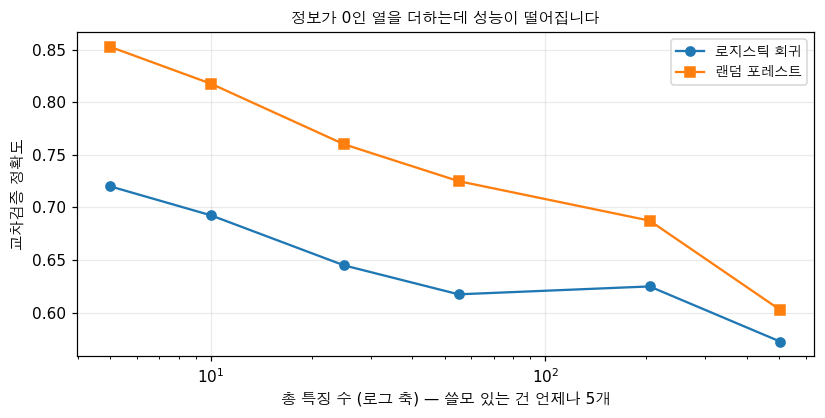


=> 쓸모 있는 특징은 처음부터 끝까지 5개 그대로입니다. 정보를 하나도 안 뺐어요.
   그런데 잡음 500개를 붙이니 로지스틱이 72.0% 에서 57.2% 로 떨어집니다.
   랜덤 포레스트도 85.2% 에서 60.2% 입니다.

   모델은 어느 열이 잡음인지 모릅니다. 데이터에서 알아내야 하죠.
   그런데 샘플이 400개뿐이라, 난수 열도 우연히 정답과 조금씩 맞아떨어집니다.
   그 우연을 규칙으로 착각하는 게 과적합이고, 열이 많을수록 그럴 기회가 늘어납니다.

   💡 이게 특징 선택이 필요한 이유 전부입니다. 나머지 절은 '어떻게 고르나' 입니다.


In [2]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

X기본, y기본 = make_classification(n_samples=400, n_features=5, n_informative=5,
                                 n_redundant=0, random_state=1)
난수 = np.random.RandomState(0)

print("쓸모 있는 특징 5개에, 정보가 0인 난수 특징을 붙여 갑니다")
print("(붙이는 열은 전부 정답과 무관한 난수입니다)\n")
print(f"{'붙인 잡음':>9}{'총 특징':>8}{'로지스틱':>11}{'랜덤 포레스트':>14}"
      f"{'로지스틱 변화':>14}{'포레스트 변화':>14}")
print("-" * 72)
기록 = []
for 추가 in (0, 5, 20, 50, 200, 500):
    X붙임 = np.hstack([X기본, 난수.randn(400, 추가)]) if 추가 else X기본
    로 = cross_val_score(LogisticRegression(max_iter=3000), X붙임, y기본, cv=5).mean()
    포 = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=0),
                        X붙임, y기본, cv=5).mean()
    if not 기록:
        기준로, 기준포 = 로, 포
    기록.append((추가, X붙임.shape[1], 로, 포))
    print(f"{추가:>9}{X붙임.shape[1]:>8}{로:>11.4f}{포:>14.4f}"
          f"{로-기준로:>+14.4f}{포-기준포:>+14.4f}")

plt.figure(figsize=(7.6, 3.9))
plt.plot([r[1] for r in 기록], [r[2] for r in 기록], "o-", label="로지스틱 회귀")
plt.plot([r[1] for r in 기록], [r[3] for r in 기록], "s-", label="랜덤 포레스트")
plt.xscale("log")
plt.xlabel("총 특징 수 (로그 축) — 쓸모 있는 건 언제나 5개"); plt.ylabel("교차검증 정확도")
plt.title("정보가 0인 열을 더하는데 성능이 떨어집니다", fontsize=10)
plt.legend(fontsize=9); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

마지막 = 기록[-1]
print(f"\n=> 쓸모 있는 특징은 처음부터 끝까지 5개 그대로입니다. 정보를 하나도 안 뺐어요.")
print(f"   그런데 잡음 {마지막[0]}개를 붙이니 로지스틱이 "
      f"{기준로:.1%} 에서 {마지막[2]:.1%} 로 떨어집니다.")
print(f"   랜덤 포레스트도 {기준포:.1%} 에서 {마지막[3]:.1%} 입니다.")
print(f"\n   모델은 어느 열이 잡음인지 모릅니다. 데이터에서 알아내야 하죠.")
print(f"   그런데 샘플이 400개뿐이라, 난수 열도 우연히 정답과 조금씩 맞아떨어집니다.")
print(f"   그 우연을 규칙으로 착각하는 게 과적합이고, 열이 많을수록 그럴 기회가 늘어납니다.")
print(f"\n   💡 이게 특징 선택이 필요한 이유 전부입니다. 나머지 절은 '어떻게 고르나' 입니다.")

> 👀 **방금 출력에서 볼 곳** (1절)
>
> `로지스틱 변화` 와 `포레스트 변화` 두 열만 보세요. 계속 음수입니다.
> 쓸모 있는 특징은 5개로 고정이고 **정보를 하나도 빼지 않았는데** 성능이 떨어집니다.
> 그림의 가로축이 로그라는 것도 보세요. 특징이 10배씩 늘 때마다 꾸준히 내려갑니다.

---

## 2. 실습용 데이터 만들기

<sub>📗 원문 "Step 1: Generate synthetic data with known feature structure"</sub>

이제 고르는 방법들을 만들 텐데, 그 전에 **채점할 방법**이 필요합니다.

실제 데이터로는 채점을 못 합니다. 어느 특징이 진짜 쓸모 있는지 아무도 모르거든요.
그래서 정답을 알고 있는 가짜 데이터를 만듭니다. 원문이 쓰는 방식 그대로예요.

특징 20개를 세 종류로 나눠 심습니다.

- `info_0` ~ `info_4`: 정답을 만드는 데 실제로 쓴 특징들
- `corr_0` ~ `corr_4`: info 를 섞어 만든 **복사본**. 정보가 겹칩니다
- `noise_0` ~ `noise_9`: 정답과 **아무 상관 없는** 난수

좋은 방법이라면 info 를 위로, noise 를 아래로 보내야 합니다.
corr 은 애매합니다. 정보는 있는데 **중복**이라서, "버려도 되는데 버리면 아깝지는 않은" 쪽이죠.

In [3]:
# 📗 원문의 make_feature_selection_data 를 그대로 옮깁니다
def 실습데이터(표본수=500, 시드=42):
    rng = np.random.RandomState(시드)

    x1 = rng.randn(표본수)
    x2 = rng.randn(표본수)
    x3 = rng.randn(표본수)
    x4 = x1 + 0.1 * rng.randn(표본수)      # x1 과 거의 같음
    x5 = x2 + 0.1 * rng.randn(표본수)      # x2 와 거의 같음
    정보 = np.column_stack([x1, x2, x3, x4, x5])

    상관 = np.column_stack([
        x1 * 0.9 + 0.1 * rng.randn(표본수),
        x2 * 0.8 + 0.2 * rng.randn(표본수),
        x3 * 0.7 + 0.3 * rng.randn(표본수),
        x1 * 0.5 + x2 * 0.5 + 0.1 * rng.randn(표본수),
        x2 * 0.6 + x3 * 0.4 + 0.1 * rng.randn(표본수),
    ])

    잡음 = rng.randn(표본수, 10) * 0.5

    X = np.hstack([정보, 상관, 잡음])
    # 정답은 x1, x2, x3 **만** 으로 만듭니다
    y = (2 * x1 - 1.5 * x2 + x3 + 0.5 * rng.randn(표본수) > 0).astype(int)

    이름 = ([f"info_{i}" for i in range(5)]
          + [f"corr_{i}" for i in range(5)]
          + [f"noise_{i}" for i in range(10)])
    return X, y, 이름


X, y, 이름 = 실습데이터()
print(f"데이터: {X.shape[0]}행 × {X.shape[1]}열, 양성 비율 {y.mean():.1%}\n")

print(f"{'특징':<10}{'정답과의 상관':>14}{'분산':>10}  무엇인가")
print("-" * 62)
설명 = (["정답 식에 직접 들어간 x1", "정답 식에 직접 들어간 x2", "정답 식에 직접 들어간 x3",
        "x1 의 복사본", "x2 의 복사본"]
       + ["x1 을 흐린 것", "x2 를 흐린 것", "x3 을 흐린 것", "x1+x2 섞음", "x2+x3 섞음"]
       + ["순수 잡음"] * 10)
for i, n in enumerate(이름):
    if i in (5, 10):
        print()
    print(f"{n:<10}{abs(np.corrcoef(X[:, i], y)[0, 1]):>14.4f}{np.var(X[:, i]):>10.4f}  {설명[i]}")

print(f"\n=> 정답을 만들 때 쓴 건 x1, x2, x3 세 개뿐입니다.")
print(f"   info_3, info_4 는 x1, x2 의 복사본이라 이름은 info 지만 새 정보는 없습니다.")
print(f"   ⚠️ '분산' 열을 눈여겨봐 두세요. 3절에서 이게 문제가 됩니다.")

데이터: 500행 × 20열, 양성 비율 50.8%

특징               정답과의 상관        분산  무엇인가
--------------------------------------------------------------
info_0            0.6433    0.9609  정답 식에 직접 들어간 x1
info_1            0.4168    0.9546  정답 식에 직접 들어간 x2
info_2            0.1735    1.0186  정답 식에 직접 들어간 x3
info_3            0.6428    0.9830  x1 의 복사본
info_4            0.4156    0.9686  x2 의 복사본

corr_0            0.6400    0.7941  x1 을 흐린 것
corr_1            0.4032    0.6585  x2 를 흐린 것
corr_2            0.1522    0.5477  x3 을 흐린 것
corr_3            0.1578    0.4477  x1+x2 섞음
corr_4            0.2292    0.5524  x2+x3 섞음

noise_0           0.0177    0.2767  순수 잡음
noise_1           0.0455    0.2345  순수 잡음
noise_2           0.0480    0.2291  순수 잡음
noise_3           0.0290    0.2431  순수 잡음
noise_4           0.0419    0.2535  순수 잡음
noise_5           0.0274    0.2663  순수 잡음
noise_6           0.0210    0.2825  순수 잡음
noise_7           0.0038    0.2796  순수 잡음
noise_8           0.0441    0.2645  순수 잡음
noise_9     

> 👀 **방금 출력에서 볼 곳** (2절)
>
> `분산` 열을 위아래로 훑어보세요. info 와 corr 은 0.45~1.02 인데 noise 는 전부 0.21~0.28 입니다.
> 원문 코드가 잡음에만 `* 0.5` 를 곱해 둬서 그렇습니다.
> **이건 실제 데이터에서는 기대할 수 없는 상황인데**, 3절에서 왜 문제인지 보입니다.
>
> 그리고 `정답과의 상관` 열도 보세요. info_2(=x3)가 0.19 로 낮습니다.
> 정답 식에서 계수가 1 로 가장 작거든요. 쓸모 있는 특징이라고 상관이 꼭 큰 건 아닙니다.

---

## 3. 분산 필터

<sub>📗 원문 "Variance Threshold"</sub>

가장 싼 방법부터 시작합니다. 어찌나 싼지 정답을 보지도 않습니다.

생각은 단순합니다. 어떤 열이 1000개 샘플 중 999개에서 똑같은 값이라면,
그 열로는 아무것도 구별할 수 없습니다. 분산이 0에 가깝죠. 버리면 됩니다.

$$\text{분산}(x) = \text{평균}\big((x - \text{평균}(x))^2\big)$$

실무에서는 늘 첫 단계로 돌립니다. 비용이 거의 없는데 상수 열이나
"99% 가 0인" 열 같은 쓰레기를 한 번에 걸러 주거든요.

> 📗 원문도 한계를 분명히 적어 뒀습니다.
> "a feature can have high variance and still be pure noise.
> Variance threshold is necessary but not sufficient."
>
> 분산이 커도 순수 잡음일 수 있습니다. 필요조건이지 충분조건이 아니에요.

In [4]:
# 📗 원문의 variance_threshold 를 그대로 옮깁니다
def 분산필터(X, 임곗값=0.01):
    분산들 = np.var(X, axis=0)
    남길것 = 분산들 > 임곗값
    return 남길것, 분산들


남길것, 분산들 = 분산필터(X, 0.01)
print(f"임곗값 0.01 로 거르면: {남길것.sum()}개 남고 {(~남길것).sum()}개 탈락")
print(f"=> 이 데이터에는 상수 열이 없어서 하나도 안 걸러집니다. 원래 그런 용도예요.\n")

# 상수 열과 거의-상수 열을 일부러 섞어 봅니다
난수3 = np.random.RandomState(1)
X더럽힘 = np.hstack([
    X,
    np.ones((len(X), 1)),                                  # 완전 상수
    np.r_[np.ones(3), np.zeros(len(X) - 3)].reshape(-1, 1),  # 997개가 0
    난수3.randn(len(X), 1) * 0.001,                         # 거의 안 변함
])
이름더럽힘 = 이름 + ["상수열", "거의상수", "미세변동"]
남길2, 분산2 = 분산필터(X더럽힘, 0.01)
print("상수 열 세 개를 일부러 섞고 다시 돌립니다")
print(f"{'특징':<10}{'분산':>12}{'통과?':>8}")
print("-" * 32)
for i in list(range(0, 2)) + list(range(20, 23)):
    print(f"{이름더럽힘[i]:<10}{분산2[i]:>12.6f}{'O' if 남길2[i] else '✘ 탈락':>8}")
print(f"\n=> 섞어 둔 쓰레기 3개가 정확히 걸러집니다. 계산은 `np.var` 한 줄이고요.")

print(f"\n⚠️ 그런데 이 데이터에서 분산으로 줄을 세우면 어떻게 될까요?")
순위 = np.argsort(-분산들)
print(f"   분산 상위 5개: {[이름[i] for i in 순위[:5]]}")
print(f"   분산 하위 5개: {[이름[i] for i in 순위[-5:]]}")
print(f"   info 를 전부 위로, noise 를 전부 아래로 보냈습니다. 완벽해 보입니다.")
print(f"\n   하지만 이건 분산 필터가 똑똑해서가 아닙니다. 2절 쪽지에서 본 그 이유죠.")
print(f"   원문 코드가 잡음에만 `* 0.5` 를 곱해서 분산을 0.25 로 깎아 뒀거든요.")

임곗값 0.01 로 거르면: 20개 남고 0개 탈락
=> 이 데이터에는 상수 열이 없어서 하나도 안 걸러집니다. 원래 그런 용도예요.

상수 열 세 개를 일부러 섞고 다시 돌립니다
특징                  분산     통과?
--------------------------------
info_0        0.960932       O
info_1        0.954566       O
상수열           0.000000    ✘ 탈락
거의상수          0.005964    ✘ 탈락
미세변동          0.000001    ✘ 탈락

=> 섞어 둔 쓰레기 3개가 정확히 걸러집니다. 계산은 `np.var` 한 줄이고요.

⚠️ 그런데 이 데이터에서 분산으로 줄을 세우면 어떻게 될까요?
   분산 상위 5개: ['info_2', 'info_3', 'info_4', 'info_0', 'info_1']
   분산 하위 5개: ['noise_4', 'noise_3', 'noise_1', 'noise_2', 'noise_9']
   info 를 전부 위로, noise 를 전부 아래로 보냈습니다. 완벽해 보입니다.

   하지만 이건 분산 필터가 똑똑해서가 아닙니다. 2절 쪽지에서 본 그 이유죠.
   원문 코드가 잡음에만 `* 0.5` 를 곱해서 분산을 0.25 로 깎아 뒀거든요.


In [5]:
# ✨ 추가 — 표준화하면 분산 필터가 어떻게 되나
from sklearn.preprocessing import StandardScaler

X표준 = StandardScaler().fit_transform(X)
print("같은 데이터를 표준화(평균 0, 분산 1)한 뒤 분산을 다시 재 봅니다\n")
print(f"   표준화 전 — info 평균 분산 {np.var(X[:, :5], axis=0).mean():.4f} / "
      f"noise 평균 분산 {np.var(X[:, 10:], axis=0).mean():.4f}")
print(f"   표준화 후 — 전부 {np.var(X표준, axis=0)[0]:.4f} "
      f"(최대 편차 {np.abs(np.var(X표준, axis=0) - 1).max():.2e})")
print(f"\n=> 표준화하면 모든 분산이 1 이 됩니다. 순위를 매길 수가 없습니다.")
print(f"   그런데 표준화는 2단원부터 늘 하던 전처리죠. 스케일이 다른 특징을 맞추려고요.")
print(f"\n   📝 그래서 분산 필터의 자리가 분명해집니다.")
print(f"      · 쓰는 곳: 상수·거의 상수 열 버리기. 표준화 전에, 가장 먼저")
print(f"      · 안 쓰는 곳: 특징 줄 세우기. 정답을 안 보니 애초에 그럴 수가 없습니다")
print(f"\n   ⚠️ 원문 예제 데이터만 보면 분산 필터가 1등처럼 보입니다. 데이터가 그렇게 생겨서예요.")
print(f"      실제 데이터에서 이런 행운은 없습니다. 다음 절부터 정답을 보는 방법으로 갑니다.")

같은 데이터를 표준화(평균 0, 분산 1)한 뒤 분산을 다시 재 봅니다

   표준화 전 — info 평균 분산 0.9771 / noise 평균 분산 0.2546
   표준화 후 — 전부 1.0000 (최대 편차 1.78e-15)

=> 표준화하면 모든 분산이 1 이 됩니다. 순위를 매길 수가 없습니다.
   그런데 표준화는 2단원부터 늘 하던 전처리죠. 스케일이 다른 특징을 맞추려고요.

   📝 그래서 분산 필터의 자리가 분명해집니다.
      · 쓰는 곳: 상수·거의 상수 열 버리기. 표준화 전에, 가장 먼저
      · 안 쓰는 곳: 특징 줄 세우기. 정답을 안 보니 애초에 그럴 수가 없습니다

   ⚠️ 원문 예제 데이터만 보면 분산 필터가 1등처럼 보입니다. 데이터가 그렇게 생겨서예요.
      실제 데이터에서 이런 행운은 없습니다. 다음 절부터 정답을 보는 방법으로 갑니다.


> 👀 **방금 출력에서 볼 곳** (3절)
>
> 먼저 첫 셀의 탈락 표를 보세요. 상수열·거의상수·미세변동 셋만 ✘ 입니다. 이게 분산 필터의 본래 용도입니다.
>
> 그다음 `분산 상위 5개` 를 보세요. info 가 전부 올라와 있어서 **똑똑해 보입니다.**
> 그런데 둘째 셀에서 표준화하면 모든 분산이 1.0000 이 되어 순위가 사라집니다.
>
> ⚠️ 정답을 보지도 않는 방법이 1등일 리가 없죠. 원문 데이터가 잡음에만 `*0.5` 를 곱해 둔 탓입니다.
> 분산 필터는 **쓰레기 버리기용**이지 줄 세우기용이 아니라는 걸 기억해 두세요.

---

## 4. 상호정보 — 상관이 놓치는 것

<sub>📗 원문 "Mutual Information"</sub>

분산은 정답을 안 봤습니다. 이제 **정답과의 관계**를 봐야죠.

가장 먼저 떠오르는 건 상관계수입니다. 그런데 상관계수에는 큰 구멍이 하나 있습니다.
직선 관계만 봅니다.

정답이 $y = x^2$ 처럼 생겼다고 해 보세요. $x$ 가 −3일 때도 $y$ 가 크고 +3일 때도 큽니다.
완벽하게 결정되는 관계인데 상관계수는 0에 가깝습니다. 올라갔다 내려오니까 상쇄되거든요.

**상호정보**는 그 구멍이 없습니다. "$x$ 를 알면 $y$ 에 대한 불확실성이 얼마나 줄어드나"를 재는데,
줄어들기만 하면 되지 어떤 모양으로 줄어드는지는 안 따집니다.

$$I(X; Y) = \sum_x \sum_y p(x, y) \log \frac{p(x, y)}{p(x)\,p(y)}$$

식이 복잡해 보이지만 뜻은 간단합니다. $X$ 와 $Y$ 가 **무관하면** $p(x,y) = p(x)p(y)$ 라서
로그 안이 1이 되고 전체가 0입니다. 관계가 있을수록 이 값이 커집니다.
(14단원 1절에서 본 독립 가정의 식이 여기 그대로 나옵니다.)

연속값은 그대로 셀 수 없으니 **구간으로 쪼개서** 셉니다.

In [6]:
# 📗 원문의 discretize / mutual_information 을 그대로 옮깁니다
def 구간나누기(x, 구간수=10):
    낮, 높 = x.min(), x.max()
    if 높 == 낮:
        return np.zeros_like(x, dtype=int)
    경계 = np.linspace(낮, 높, 구간수 + 1)
    return np.digitize(x, 경계[1:-1])


def 상호정보(X, y, 구간수=10):
    표본수, 특징수 = X.shape
    점수 = np.zeros(특징수)
    y값들, y개수 = np.unique(y, return_counts=True)
    p_y = y개수 / 표본수

    for f in range(특징수):
        x구간 = 구간나누기(X[:, f], 구간수)
        x값들, x개수 = np.unique(x구간, return_counts=True)
        p_x = dict(zip(x값들, x개수 / 표본수))

        점 = 0.0
        for xv in x값들:
            for yi, yv in enumerate(y값들):
                p_xy = np.sum((x구간 == xv) & (y == yv)) / 표본수
                if p_xy > 0:
                    점 += p_xy * np.log(p_xy / (p_x[xv] * p_y[yi]))
        점수[f] = 점
    return 점수


# 먼저 '상관이 놓치는' 상황을 직접 만듭니다
from scipy.stats import pearsonr
from sklearn.feature_selection import mutual_info_classif

난수4 = np.random.RandomState(0)
n4 = 2000
x = 난수4.uniform(-3, 3, n4)
관계들 = {
    "직선     y ~ x":     x,
    "2차 곡선 y ~ x²":    x ** 2,
    "절댓값   y ~ |x|":   np.abs(x),
    "주기     y ~ sin2x": np.sin(2 * x),
}

print("같은 x 로, 정답을 만드는 '모양'만 바꿔 가며 두 지표를 비교합니다\n")
print(f"{'관계의 모양':<20}{'|피어슨 상관|':>14}{'상호정보':>11}  판정")
print("-" * 64)
for 라벨, 신호 in 관계들.items():
    yy = (신호 + 0.3 * 난수4.randn(n4) > np.median(신호)).astype(int)
    r = abs(pearsonr(x, yy)[0])
    m = mutual_info_classif(x.reshape(-1, 1), yy, random_state=0)[0]
    판정 = "⚠️ 상관이 놓침" if (r < 0.1 and m > 0.1) else "둘 다 잡아냄"
    print(f"{라벨:<20}{r:>14.4f}{m:>11.4f}  {판정}")

print(f"\n=> 2차 곡선과 절댓값을 보세요. 상관이 0.03 아래입니다. 사실상 0이죠.")
print(f"   상관계수만 보고 특징을 고르면 이 둘을 '쓸모없다'며 버립니다.")
print(f"   그런데 상호정보는 0.5 가 넘습니다. 관계가 분명히 있다고 말하고 있어요.")
print(f"\n   📗 원문: 'A feature might have zero correlation with the target but")
print(f"   high mutual information because the relationship is quadratic or periodic.'")
print(f"   정확히 재현됩니다.")

같은 x 로, 정답을 만드는 '모양'만 바꿔 가며 두 지표를 비교합니다

관계의 모양                    |피어슨 상관|       상호정보  판정
----------------------------------------------------------------
직선     y ~ x                0.8617     0.6009  둘 다 잡아냄
2차 곡선 y ~ x²                0.0278     0.6397  ⚠️ 상관이 놓침
절댓값   y ~ |x|               0.0153     0.5182  ⚠️ 상관이 놓침
주기     y ~ sin2x            0.3788     0.5435  둘 다 잡아냄

=> 2차 곡선과 절댓값을 보세요. 상관이 0.03 아래입니다. 사실상 0이죠.
   상관계수만 보고 특징을 고르면 이 둘을 '쓸모없다'며 버립니다.
   그런데 상호정보는 0.5 가 넘습니다. 관계가 분명히 있다고 말하고 있어요.

   📗 원문: 'A feature might have zero correlation with the target but
   high mutual information because the relationship is quadratic or periodic.'
   정확히 재현됩니다.


In [7]:
# 직접 만든 상호정보가 sklearn 과 같은 순위를 내는지
내점수 = 상호정보(X, y, 구간수=10)
sk점수 = mutual_info_classif(X, y, random_state=0)
from scipy.stats import spearmanr

print(f"직접 만든 것 vs sklearn — 순위 상관 {spearmanr(내점수, sk점수).correlation:.4f}\n")
print(f"{'특징':<10}{'내 상호정보':>12}{'sklearn':>10}{'|상관|':>9}  종류")
print("-" * 54)
순위 = np.argsort(-내점수)
for i in 순위:
    종류 = "정보" if i < 5 else ("중복" if i < 10 else "잡음")
    print(f"{이름[i]:<10}{내점수[i]:>12.4f}{sk점수[i]:>10.4f}"
          f"{abs(np.corrcoef(X[:, i], y)[0, 1]):>9.4f}  {종류}")

상위5 = set(순위[:5])
print(f"\n=> 상위 5개: {sorted(이름[i] for i in 상위5)}")
print(f"   그중 info_* 는 {sum(1 for i in 상위5 if i < 5)}개입니다.")
print(f"   잡음 10개는 전부 아래쪽에 깔려 있죠. 제 역할을 합니다.")
print(f"\n   ⚠️ 다만 corr_0 이 info_2 보다 위에 있습니다.")
print(f"      corr_0 은 x1 을 흐린 복사본이라 정보가 중복인데도 점수가 높습니다.")
print(f"      필터는 특징을 하나씩 따로 보니까요. '이미 info_0 이 있으니 넌 필요 없다'를 못 합니다.")
print(f"      => 중복을 걸러내려면 특징을 함께 보는 방법이 필요합니다. 5절입니다.")

직접 만든 것 vs sklearn — 순위 상관 0.9142

특징              내 상호정보   sklearn     |상관|  종류
------------------------------------------------------
info_0          0.2669    0.2673   0.6433  정보
info_3          0.2612    0.2705   0.6428  정보
corr_0          0.2490    0.2623   0.6400  중복
info_4          0.1044    0.1038   0.4156  정보
info_1          0.0988    0.1198   0.4168  정보
corr_1          0.0977    0.0655   0.4032  중복
corr_4          0.0374    0.0454   0.2292  중복
corr_2          0.0217    0.0385   0.1522  중복
info_2          0.0206    0.0290   0.1735  정보
noise_9         0.0177    0.0202   0.0963  잡음
noise_2         0.0176    0.0076   0.0480  잡음
corr_3          0.0153    0.0278   0.1578  중복
noise_0         0.0150    0.0038   0.0177  잡음
noise_5         0.0142    0.0114   0.0274  잡음
noise_3         0.0124    0.0207   0.0290  잡음
noise_1         0.0102    0.0209   0.0455  잡음
noise_6         0.0079    0.0000   0.0210  잡음
noise_4         0.0078    0.0000   0.0419  잡음
noise_7         0.0062    0.0101   0

> 👀 **방금 출력에서 볼 곳** (4절)
>
> 첫 셀에서 `2차 곡선` 과 `절댓값` 행만 보세요. 상관이 **0.03** 인데 상호정보는 **0.53** 이 넘습니다.
> 상관계수만 쓰면 이 특징들을 쓸모없다고 버린다는 뜻입니다. 원문 주장이 그대로 재현됩니다.
>
> 둘째 셀에서는 순위표의 `종류` 열을 위에서 아래로 훑어보세요.
> 잡음 10개가 전부 바닥에 깔립니다. 그런데 **corr_0 이 info_2 보다 위**에 있습니다.
> 중복인데도 점수가 높은 거죠. 필터가 특징을 하나씩만 보기 때문이고, 이게 5절로 넘어가는 이유입니다.

---

## 5. RFE — 훈련하고, 줄 세우고, 자르고, 반복

<sub>📗 원문 "Recursive Feature Elimination (RFE)"</sub>

필터의 한계를 봤습니다. 특징을 **하나씩** 보니까 "이미 비슷한 게 있다"를 모릅니다.

그럼 **다 같이 놓고** 보면 되겠죠. 모델에 전부 넣고 학습시켜서,
모델이 "얘는 별로 안 쓴다"고 하는 걸 하나 빼고, 또 학습시키고, 또 빼고….
이게 **RFE**(재귀적 특징 제거)입니다.

> 📗 원문의 네 단계
> 1. 모든 특징으로 모델을 학습합니다
> 2. 중요도로 줄을 세웁니다 (선형이면 계수 크기, 트리면 불순도 감소)
> 3. 가장 덜 중요한 걸 뺍니다
> 4. 목표 개수가 될 때까지 반복합니다

핵심은 3번 다음에 다시 2번으로 돌아간다는 점입니다.
특징 하나를 빼면 남은 특징들의 중요도가 **바뀌거든요.**
info_0 을 빼면 그동안 묻혀 있던 corr_0 의 중요도가 갑자기 올라가는 식이죠.

대가는 속도입니다. 📗 원문 말대로 특징 500개를 10개로 줄이려면 **490번 학습**해야 합니다.

In [8]:
# 📗 원문의 simple_logistic_importance / rfe 를 그대로 옮깁니다
def 로지스틱중요도(X, y, 학습률=0.1, 반복=100):
    표본수, 특징수 = X.shape
    w = np.zeros(특징수)
    b = 0.0
    for _ in range(반복):
        z = X @ w + b
        예측 = 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
        오차 = 예측 - y
        w -= 학습률 * (X.T @ 오차) / 표본수
        b -= 학습률 * np.mean(오차)
    return w, b


def RFE직접(X, y, 남길개수=5, 학습률=0.1, 반복=100, 기록남기기=False):
    전체 = X.shape[1]
    남은것 = list(range(전체))
    순위 = np.ones(전체, dtype=int)
    현재순위 = 전체
    발자취 = []

    while len(남은것) > 남길개수:
        w, _ = 로지스틱중요도(X[:, 남은것], y, 학습률, 반복)
        중요도 = np.abs(w)
        꼴찌 = int(np.argmin(중요도))
        뺀것 = 남은것[꼴찌]
        if 기록남기기:
            발자취.append((len(남은것), 이름[뺀것], float(중요도[꼴찌])))
        순위[뺀것] = 현재순위
        현재순위 -= 1
        남은것.pop(꼴찌)

    for i in 남은것:
        순위[i] = 1
    return 순위 == 1, 순위, 발자취


선택, 순위, 발자취 = RFE직접(X, y, 남길개수=5, 기록남기기=True)

print("한 번에 하나씩 빼 나갑니다 (처음 8번과 마지막 3번)\n")
print(f"{'남은 특징 수':>11}{'뺀 특징':>11}{'그때의 중요도':>14}")
print("-" * 38)
for 남음, 뺀, 중 in 발자취[:8]:
    print(f"{남음:>11}{뺀:>11}{중:>14.5f}")
print(f"{'...':>11}")
for 남음, 뺀, 중 in 발자취[-3:]:
    print(f"{남음:>11}{뺀:>11}{중:>14.5f}")

print(f"\n최종 선택: {sorted(이름[i] for i in np.where(선택)[0])}")
print(f"   그중 info_* 는 {sum(1 for i in np.where(선택)[0] if i < 5)}개")

남은corr = [이름[i] for i in np.where(선택)[0] if 5 <= i < 10]
빠진info = [이름[i] for i in range(5) if not 선택[i]]
print(f"\n=> '뺀 특징' 열을 위에서 아래로 보세요. 잡음 10개가 먼저 다 빠집니다.")
print(f"   거기까지는 기대한 대로입니다. 그다음이 흥미롭습니다.")
print(f"\n   중복인데 살아남은 것: {남은corr if 남은corr else '없음'}")
print(f"   정보인데 빠진 것    : {빠진info if 빠진info else '없음'}")
print(f"\n   ⚠️ 이름만 보면 틀린 것 같지만, 사실 RFE 쪽이 맞습니다.")
print(f"      info_2 는 x3 인데, 정답 식 `2·x1 - 1.5·x2 + x3` 에서 계수가 1 로 가장 작습니다.")
print(f"      반면 corr_0 은 x1 을 0.9 배 한 것이라 계수 2 짜리 신호를 거의 그대로 담고 있죠.")
print(f"      즉 '정보냐 중복이냐' 라는 이름표보다 실제 기여도가 중요합니다.")
print(f"\n   💡 여기서 특징 선택의 한계가 하나 보입니다.")
print(f"      RFE 는 '어느 열이 예측에 쓸모 있나' 를 고릅니다.")
print(f"      '어느 열이 원인인가' 를 고르는 게 아닙니다. 둘은 다른 질문이에요.")

한 번에 하나씩 빼 나갑니다 (처음 8번과 마지막 3번)

    남은 특징 수       뺀 특징       그때의 중요도
--------------------------------------
         20    noise_4       0.00354
         19    noise_0       0.01659
         18    noise_7       0.02623
         17    noise_3       0.03956
         16    noise_5       0.04043
         15    noise_6       0.05063
         14    noise_1       0.07317
         13    noise_8       0.07787
        ...
          8     corr_2       0.31500
          7     corr_1       0.43787
          6     info_2       0.63520

최종 선택: ['corr_0', 'info_0', 'info_1', 'info_3', 'info_4']
   그중 info_* 는 4개

=> '뺀 특징' 열을 위에서 아래로 보세요. 잡음 10개가 먼저 다 빠집니다.
   거기까지는 기대한 대로입니다. 그다음이 흥미롭습니다.

   중복인데 살아남은 것: ['corr_0']
   정보인데 빠진 것    : ['info_2']

   ⚠️ 이름만 보면 틀린 것 같지만, 사실 RFE 쪽이 맞습니다.
      info_2 는 x3 인데, 정답 식 `2·x1 - 1.5·x2 + x3` 에서 계수가 1 로 가장 작습니다.
      반면 corr_0 은 x1 을 0.9 배 한 것이라 계수 2 짜리 신호를 거의 그대로 담고 있죠.
      즉 '정보냐 중복이냐' 라는 이름표보다 실제 기여도가 중요합니다.

   💡 여기서 특징 선택의 한계가 하나 보입니다.
      RFE 는 '어느 열

In [9]:
# sklearn RFE 와 맞춰 보고, 비용도 재 봅니다
from sklearn.feature_selection import RFE

sk = RFE(LogisticRegression(max_iter=2000), n_features_to_select=5).fit(X, y)
내것 = set(np.where(선택)[0])
sk것 = set(np.where(sk.support_)[0])
print(f"직접 만든 것 선택: {sorted(이름[i] for i in 내것)}")
print(f"sklearn 선택    : {sorted(이름[i] for i in sk것)}")
print(f"겹치는 개수: {len(내것 & sk것)}/5\n")

print("특징 수를 늘려 가며 학습 횟수와 시간을 재 봅니다 (목표는 늘 10개)")
print(f"{'총 특징':>8}{'학습 횟수':>10}{'step=1 (초)':>13}{'step=10% (초)':>15}"
      f"{'L1 한 번 (초)':>14}")
print("-" * 62)
from sklearn.linear_model import LogisticRegression as LR
for 특징수 in (30, 60, 120, 240):
    Xr, yr = make_classification(n_samples=600, n_features=특징수,
                                 n_informative=8, random_state=2)
    t0 = time.time(); RFE(LR(max_iter=1000), n_features_to_select=10, step=1).fit(Xr, yr)
    한개씩 = time.time() - t0
    t0 = time.time(); RFE(LR(max_iter=1000), n_features_to_select=10, step=0.1).fit(Xr, yr)
    뭉텅이 = time.time() - t0
    t0 = time.time(); LR(penalty="l1", solver="liblinear", C=0.05).fit(Xr, yr)
    L1시간 = time.time() - t0
    print(f"{특징수:>8}{특징수-10:>10}{한개씩:>13.3f}{뭉텅이:>15.3f}{L1시간:>14.4f}")

print(f"\n=> `학습 횟수` 열이 특징 수에 비례해서 늘어납니다. 240개면 230번이죠.")
print(f"   📗 원문: '500개에서 10개로 줄이면 490번 학습' 이 그대로입니다.")
print(f"\n   ⚠️ 시간 열은 들쭉날쭉합니다. 특징 수뿐 아니라 수렴 난이도에도 좌우되거든요.")
print(f"      학습 '횟수' 가 RFE 비용의 본질이고, 실제 시간은 모델에 따라 달라집니다.")
print(f"\n   step=10% 열을 보세요. 한 번에 10%씩 빼면 훨씬 빠릅니다.")
print(f"   대신 '하나 뺄 때마다 다시 줄 세운다'는 장점이 그만큼 흐려집니다.")
print(f"   💡 특징이 수백 개면 보통 step 을 올려 씁니다. 정확도와 시간의 맞바꿈이에요.")
print(f"\n   맨 오른쪽 L1 열과 비교해 보세요. 한 번만 학습합니다. 그게 6절입니다.")

직접 만든 것 선택: ['corr_0', 'info_0', 'info_1', 'info_3', 'info_4']
sklearn 선택    : ['corr_0', 'info_0', 'info_1', 'info_2', 'info_3']
겹치는 개수: 4/5

특징 수를 늘려 가며 학습 횟수와 시간을 재 봅니다 (목표는 늘 10개)
    총 특징     학습 횟수   step=1 (초)   step=10% (초)    L1 한 번 (초)
--------------------------------------------------------------
      30        20        0.057          0.024        0.0010
      60        50        0.195          0.021        0.0012
     120       110        0.803          0.049        0.0022
     240       230        2.291          0.143        0.0042

=> `학습 횟수` 열이 특징 수에 비례해서 늘어납니다. 240개면 230번이죠.
   📗 원문: '500개에서 10개로 줄이면 490번 학습' 이 그대로입니다.

   ⚠️ 시간 열은 들쭉날쭉합니다. 특징 수뿐 아니라 수렴 난이도에도 좌우되거든요.
      학습 '횟수' 가 RFE 비용의 본질이고, 실제 시간은 모델에 따라 달라집니다.

   step=10% 열을 보세요. 한 번에 10%씩 빼면 훨씬 빠릅니다.
   대신 '하나 뺄 때마다 다시 줄 세운다'는 장점이 그만큼 흐려집니다.
   💡 특징이 수백 개면 보통 step 을 올려 씁니다. 정확도와 시간의 맞바꿈이에요.

   맨 오른쪽 L1 열과 비교해 보세요. 한 번만 학습합니다. 그게 6절입니다.


> 👀 **방금 출력에서 볼 곳** (5절)
>
> 첫 셀의 `뺀 특징` 열을 위에서 아래로 따라가세요. 잡음이 먼저 빠집니다.
> 그리고 `최종 선택에 남은 corr_*` 줄을 보세요. 4절에서 상위권에 있던 **중복 특징이 사라졌습니다.**
> 모델이 특징을 함께 보기 때문에 "이미 info_0 이 있으니 복사본은 필요 없다"가 됩니다.
>
> 둘째 셀에서는 `학습 횟수` 열이 특징 수에 비례해 늘어나는 걸 보세요. 이게 RFE 의 값입니다.
> 맨 오른쪽 `L1 한 번` 열과 비교하면 수백 배 차이가 납니다.

---

## 6. L1 규제 — 학습하면서 고르기

<sub>📗 원문 "L1 (Lasso) Regularization"</sub>

RFE 는 잘 고르지만 느립니다. 고르는 단계와 학습하는 단계가 **따로** 있어서 그래요.

그럼 둘을 합치면 어떨까요? **학습하면서 동시에 고르는** 방법이 L1 규제입니다.

손실 함수에 가중치의 절댓값 합을 더합니다.

$$\text{손실} = \text{예측 오차} + \alpha \sum_i |w_i|$$

이렇게 하면 쓸모없는 특징의 가중치가 **정확히 0** 이 됩니다.
0에 가까운 게 아니라 진짜 0이에요. 그 특징은 예측에 아무 기여를 안 하니 사실상 제거된 셈이죠.

### 왜 하필 정확히 0인가

10단원 5절에서 L2 규제를 봤습니다. L2 는 가중치를 **줄이기만** 하지 0으로 만들지는 않아요.
차이가 어디서 날까요?

L1 의 제약 영역은 **마름모**입니다. 뾰족한 모서리가 축 위에 있죠.
최적점이 그 모서리에 걸리기 쉬운데, 모서리는 **어떤 좌표가 0인 지점**입니다.
L2 의 제약 영역은 **원**이라 모서리가 없습니다. 그래서 0에 닿기 어렵고요.

구현에서는 이걸 **소프트 임곗값**이라는 한 줄로 처리합니다.
경사하강으로 가중치를 한 발 옮긴 뒤, 절댓값이 작으면 그냥 0으로 눌러 버리는 거예요.

In [10]:
# 📗 원문의 soft_threshold / l1_feature_selection 을 그대로 옮깁니다
def 소프트임곗값(w, 양):
    # |w| 가 '양' 보다 작으면 0으로, 크면 그만큼 0쪽으로 당깁니다
    return np.sign(w) * np.maximum(np.abs(w) - 양, 0)


def L1선택(X, y, 알파=0.1, 학습률=0.01, 반복=500):
    표본수, 특징수 = X.shape
    w = np.zeros(특징수)
    b = 0.0
    for _ in range(반복):
        z = X @ w + b
        예측 = 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
        오차 = 예측 - y
        w -= 학습률 * (X.T @ 오차) / 표본수
        w = 소프트임곗값(w, 학습률 * 알파)      # ← 이 한 줄이 L1 입니다
        b -= 학습률 * np.mean(오차)
    return np.abs(w) > 1e-6, w


# 소프트 임곗값이 하는 일을 눈으로
값들 = np.linspace(-1, 1, 9)
print("소프트 임곗값(양=0.3) 이 하는 일")
print(f"   들어간 값: {값들.round(2)}")
print(f"   나온 값  : {소프트임곗값(값들, 0.3).round(2)}")
print(f"   => 가운데 0.3 이내는 전부 정확히 0. 바깥은 0쪽으로 0.3 만큼 당겨집니다.\n")

고른것, w = L1선택(X, y, 알파=0.1, 학습률=0.05, 반복=3000)
print(f"알파=0.1 로 학습한 결과: {고른것.sum()}개 생존, {(~고른것).sum()}개가 0\n")
print(f"{'특징':<10}{'가중치':>11}  종류")
print("-" * 36)
for i in np.argsort(-np.abs(w)):
    if np.abs(w[i]) > 1e-6:
        종류 = "정보" if i < 5 else ("중복" if i < 10 else "잡음")
        print(f"{이름[i]:<10}{w[i]:>11.4f}  {종류}")
print(f"   (나머지 {(~고른것).sum()}개는 정확히 0)")

산자리 = np.where(고른것)[0]
print(f"\n=> 살아남은 {len(산자리)}개의 구성: "
      f"info {sum(1 for i in 산자리 if i<5)} / corr {sum(1 for i in 산자리 if 5<=i<10)} "
      f"/ noise {sum(1 for i in 산자리 if i>=10)}")
print(f"   5절의 RFE 가 corr_0 을 남겼던 것과 대조적이죠.")
print(f"   L1 은 서로 닮은 특징 중 하나만 남기는 성질이 강합니다.")
print(f"   둘 다 쓰면 패널티를 두 번 내야 하니, 한쪽에 몰아주는 게 손실이 더 작거든요.")

소프트 임곗값(양=0.3) 이 하는 일
   들어간 값: [-1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75  1.  ]
   나온 값  : [-0.7  -0.45 -0.2  -0.    0.    0.    0.2   0.45  0.7 ]
   => 가운데 0.3 이내는 전부 정확히 0. 바깥은 0쪽으로 0.3 만큼 당겨집니다.

알파=0.1 로 학습한 결과: 5개 생존, 15개가 0

특징                가중치  종류
------------------------------------
info_3         0.6011  정보
info_0         0.5334  정보
info_4        -0.2572  정보
info_1        -0.2243  정보
info_2         0.0368  정보
   (나머지 15개는 정확히 0)

=> 살아남은 5개의 구성: info 5 / corr 0 / noise 0
   5절의 RFE 가 corr_0 을 남겼던 것과 대조적이죠.
   L1 은 서로 닮은 특징 중 하나만 남기는 성질이 강합니다.
   둘 다 쓰면 패널티를 두 번 내야 하니, 한쪽에 몰아주는 게 손실이 더 작거든요.


In [11]:
# 알파를 바꿔 가며 — 규제 세기가 곧 선택 개수입니다
print("알파를 키우면 몇 개가 살아남나")
print(f"{'알파':>8}{'생존 개수':>10}{'info 중':>9}{'corr 중':>9}{'noise 중':>10}  살아남은 것")
print("-" * 76)
for 알파 in (0.001, 0.01, 0.03, 0.1, 0.3, 0.5):
    고름, ww = L1선택(X, y, 알파=알파, 학습률=0.05, 반복=3000)
    자리 = np.where(고름)[0]
    i정보 = sum(1 for i in 자리 if i < 5)
    i중복 = sum(1 for i in 자리 if 5 <= i < 10)
    i잡음 = sum(1 for i in 자리 if i >= 10)
    보임 = ", ".join(이름[i] for i in 자리[:5]) + ("..." if len(자리) > 5 else "")
    print(f"{알파:>8.3f}{len(자리):>10}{i정보:>9}{i중복:>9}{i잡음:>10}  {보임}")

print(f"\n=> 알파가 규제 세기이자 선택 개수 손잡이입니다. 키우면 적게 남습니다.")
print(f"   `noise 중` 열이 먼저 0 이 되고, 그다음 `corr 중` 이 0 이 됩니다.")
print(f"   마지막까지 버티는 게 info 죠. 우리가 원하던 순서 그대로입니다.")
print(f"\n   ⚠️ 끝까지 키우면 info 도 죽습니다. 맨 아랫줄을 보세요.")
print(f"      규제가 너무 세면 쓸모 있는 것까지 0 이 됩니다. 10단원의 과소적합이에요.")
print(f"\n   ⚠️ 그런데 알파를 얼마로 둘지는 데이터가 안 알려 줍니다.")
print(f"      12단원처럼 검증셋으로 골라야 합니다. sklearn 의 `LassoCV` 가 그 일을 해 줍니다.")
print(f"\n   ⚠️ 그리고 📗 원문이 적어 둔 한계도 기억하세요.")
print(f"      'only works for linear models. Cannot capture nonlinear feature importance.'")
print(f"      곡선 관계는 4절의 상호정보나 다음 절의 트리가 봅니다.")

알파를 키우면 몇 개가 살아남나
      알파     생존 개수   info 중   corr 중   noise 중  살아남은 것
----------------------------------------------------------------------------
   0.001        17        5        3         9  info_0, info_1, info_2, info_3, info_4...
   0.010         9        5        3         1  info_0, info_1, info_2, info_3, info_4...
   0.030         6        5        1         0  info_0, info_1, info_2, info_3, info_4...
   0.100         5        5        0         0  info_0, info_1, info_2, info_3, info_4
   0.300         1        1        0         0  info_3
   0.500         0        0        0         0  

=> 알파가 규제 세기이자 선택 개수 손잡이입니다. 키우면 적게 남습니다.
   `noise 중` 열이 먼저 0 이 되고, 그다음 `corr 중` 이 0 이 됩니다.
   마지막까지 버티는 게 info 죠. 우리가 원하던 순서 그대로입니다.

   ⚠️ 끝까지 키우면 info 도 죽습니다. 맨 아랫줄을 보세요.
      규제가 너무 세면 쓸모 있는 것까지 0 이 됩니다. 10단원의 과소적합이에요.

   ⚠️ 그런데 알파를 얼마로 둘지는 데이터가 안 알려 줍니다.
      12단원처럼 검증셋으로 골라야 합니다. sklearn 의 `LassoCV` 가 그 일을 해 줍니다.

   ⚠️ 그리고 📗 원문이 적어 둔 한계도 기억하세요.
      'only works for linear m

> 👀 **방금 출력에서 볼 곳** (6절)
>
> 첫 셀에서 소프트 임곗값의 '들어간 값 → 나온 값' 두 줄을 비교하세요.
> 가운데 값들이 **정확히 0** 이 됩니다. L1 이 하는 일이 이 한 줄에 다 들어 있습니다.
>
> 그다음 가중치 표의 `종류` 열을 보세요. 살아남은 게 info 고, corr 은 0 이 됐습니다.
> 서로 닮은 특징 중 하나만 남기는 성질입니다.
>
> 둘째 셀에서는 `info 중 / corr 중 / noise 중` 세 열을 가로로 보세요.
> 알파를 키우면 **잡음 → 중복 → 정보** 순으로 죽습니다. 원하는 순서입니다.

---

## 7. 트리 중요도 (+ ⚠️ 고유값 편향)

<sub>📗 원문 "Tree-Based Feature Importance"</sub>

L1 은 선형 모델 전용입니다. 곡선 관계는 못 보죠.

트리는 다릅니다. 4단원에서 봤듯 트리는 쪼갤 때마다 **불순도가 얼마나 줄었는지**를 계산합니다.
"이 특징으로 쪼갰더니 많이 깔끔해졌다"면 그 특징이 중요한 거예요.
그걸 나무 전체, 숲 전체에서 더하면 특징별 중요도가 나옵니다.

곡선이든 상호작용이든 트리가 쪼갤 수만 있으면 잡힙니다. 공짜로 따라오는 셈이죠.
모델을 학습하면 중요도가 그냥 나오니까요.

### 그런데 함정이 있습니다

> 📗 원문의 경고: "tree-based importance is biased toward features with many unique values
> (high cardinality). A random ID column will appear important because it perfectly
> splits every sample."

고유값이 많은 특징이 유리합니다. 쪼갤 자리가 많으니 우연히 잘 맞는 지점도 찾기 쉽거든요.
원문은 "무작위 ID 열이 중요해 보일 것"이라고까지 말합니다.

정말 그런지 재 보겠습니다. 결과가 원문 표현만큼 극적이지는 않습니다.

In [12]:
# 📗 원문의 gini_impurity / best_split / tree_importance 를 그대로 옮깁니다
def 지니(y):
    if len(y) == 0:
        return 0.0
    _, 개수 = np.unique(y, return_counts=True)
    확률 = 개수 / len(y)
    return 1.0 - np.sum(확률 ** 2)


def 최적분할(X, y, 특징):
    값들 = np.unique(X[:, 특징])
    if len(값들) <= 1:
        return None, -1.0
    최적경계, 최대이득 = None, -1.0
    부모 = 지니(y)
    n = len(y)
    for i in range(len(값들) - 1):
        경계 = (값들[i] + 값들[i + 1]) / 2.0
        왼 = X[:, 특징] <= 경계
        n왼, n오 = int(왼.sum()), int((~왼).sum())
        if n왼 == 0 or n오 == 0:
            continue
        이득 = 부모 - (n왼 / n) * 지니(y[왼]) - (n오 / n) * 지니(y[~왼])
        if 이득 > 최대이득:
            최대이득, 최적경계 = 이득, 경계
    return 최적경계, 최대이득


def _나무중요도(X, y, 쓸특징, 최대깊이, 깊이=0):
    중요도 = np.zeros(X.shape[1])
    if 깊이 >= 최대깊이 or len(np.unique(y)) <= 1 or len(y) < 4:
        return 중요도
    최적특징, 최적경계, 최대이득 = None, None, -1.0
    for f in 쓸특징:
        경계, 이득 = 최적분할(X, y, f)
        if 이득 > 최대이득:
            최대이득, 최적특징, 최적경계 = 이득, f, 경계
    if 최적특징 is None or 최대이득 <= 0:
        return 중요도
    중요도[최적특징] += 최대이득 * len(y)       # 이득 × 샘플 수를 쌓습니다
    왼 = X[:, 최적특징] <= 최적경계
    중요도 += _나무중요도(X[왼], y[왼], 쓸특징, 최대깊이, 깊이 + 1)
    중요도 += _나무중요도(X[~왼], y[~왼], 쓸특징, 최대깊이, 깊이 + 1)
    return 중요도


def 트리중요도(X, y, 나무수=50, 최대깊이=5, 시드=42):
    rng = np.random.RandomState(시드)
    표본수, 특징수 = X.shape
    중요도 = np.zeros(특징수)
    for _ in range(나무수):
        뽑기 = rng.choice(표본수, size=표본수, replace=True)
        쓸특징 = rng.choice(특징수, size=max(1, int(np.sqrt(특징수))), replace=False)
        중요도 += _나무중요도(X[뽑기], y[뽑기], 쓸특징, 최대깊이)
    합 = 중요도.sum()
    return 중요도 / 합 if 합 > 0 else 중요도


내중요도 = 트리중요도(X, y, 나무수=50, 최대깊이=5)
숲 = RandomForestClassifier(n_estimators=300, random_state=0).fit(X, y)
print(f"직접 만든 것 vs sklearn — 순위 상관 "
      f"{spearmanr(내중요도, 숲.feature_importances_).correlation:.4f}\n")
print(f"{'특징':<10}{'내 트리중요도':>14}{'sklearn':>11}  종류")
print("-" * 50)
for i in np.argsort(-내중요도)[:8]:
    종류 = "정보" if i < 5 else ("중복" if i < 10 else "잡음")
    print(f"{이름[i]:<10}{내중요도[i]:>14.4f}{숲.feature_importances_[i]:>11.4f}  {종류}")
print(f"   (하위 12개 생략)")
상위5 = set(np.argsort(-숲.feature_importances_)[:5])
print(f"\n=> 상위 5개 중 info_* 는 {sum(1 for i in 상위5 if i < 5)}개입니다.")
print(f"   4절의 상호정보와 비슷하게, 중복(corr_0)이 섞여 들어옵니다.")

직접 만든 것 vs sklearn — 순위 상관 0.8887

특징               내 트리중요도    sklearn  종류
--------------------------------------------------
corr_0            0.2333     0.1713  중복
info_3            0.1986     0.1434  정보
info_0            0.0974     0.1859  정보
info_4            0.0742     0.0703  정보
info_1            0.0606     0.0729  정보
corr_1            0.0578     0.0693  중복
corr_2            0.0532     0.0368  중복
corr_3            0.0492     0.0396  중복
   (하위 12개 생략)

=> 상위 5개 중 info_* 는 4개입니다.
   4절의 상호정보와 비슷하게, 중복(corr_0)이 섞여 들어옵니다.


In [13]:
# ⚠️ 원문의 '고유값 편향' 주장을 직접 재 봅니다
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

난수7 = np.random.RandomState(7)
n7 = 1500
진짜 = 난수7.randint(0, 2, n7).astype(float)             # 진짜 신호인데 고유값이 2개뿐
y7 = (진짜 + 0.45 * 난수7.randn(n7) > 0.5).astype(int)

열들 = {
    "진짜 신호 (2범주)":   진짜,
    "무의미 2범주":        난수7.randint(0, 2, n7).astype(float),
    "무의미 4범주":        난수7.randint(0, 4, n7).astype(float),
    "무의미 20범주":       난수7.randint(0, 20, n7).astype(float),
    "무의미 연속값":        난수7.randn(n7),
}
X7 = np.column_stack(list(열들.values()))
이름7 = list(열들)

숲7 = RandomForestClassifier(n_estimators=400, random_state=0).fit(X7, y7)
X7훈, X7테, y7훈, y7테 = train_test_split(X7, y7, test_size=0.3, random_state=0, stratify=y7)
숲7b = RandomForestClassifier(n_estimators=400, random_state=0).fit(X7훈, y7훈)
순열 = permutation_importance(숲7b, X7테, y7테, n_repeats=30, random_state=0)

print("정답은 '진짜 신호' 하나로만 만들었습니다. 나머지 넷은 전부 무의미한 난수입니다.\n")
print(f"{'특징':<18}{'고유값 수':>10}{'트리 중요도':>13}{'순열 중요도':>13}")
print("-" * 56)
for i, nm in enumerate(이름7):
    print(f"{nm:<18}{len(np.unique(X7[:, i])):>10}"
          f"{숲7.feature_importances_[i]:>13.4f}{순열.importances_mean[i]:>13.4f}")

무의미 = 숲7.feature_importances_[1:]
print(f"\n=> ⚠️ 📗 원문의 주장을 그대로 확인하지는 못했습니다.")
print(f"   원문은 '무작위 ID 열이 중요해 보인다'고 하는데, 1위는 진짜 신호입니다.")
print(f"   진짜 신호가 있으면 무의미한 열이 그걸 이기지는 못합니다.")
print(f"\n   ✅ 그런데 무의미한 넷끼리 비교하면 편향이 선명합니다.")
print(f"      전부 똑같이 쓸모없는 열인데 트리 중요도가")
print(f"      2범주 {무의미[0]:.4f} -> 연속값 {무의미[3]:.4f} 로 "
      f"{무의미[3]/max(무의미[0],1e-9):.0f}배 차이가 납니다.")
print(f"      고유값이 많을수록 쪼갤 자리가 많아 우연히 잘 맞는 지점을 찾기 때문입니다.")
print(f"\n   그리고 `순열 중요도` 열을 보세요. 무의미한 넷이 전부 0 근처입니다.")
print(f"   편향이 없습니다. 그게 8절입니다.")
print(f"\n   📝 정리하면 이렇게 말하는 게 정확합니다.")
print(f"      '트리 중요도는 고유값이 많은 쪽을 과대평가한다. 진짜 신호를 이기지는 못하지만,")
print(f"       쓸모없는 것들 사이의 순위는 믿을 수 없다.'")

정답은 '진짜 신호' 하나로만 만들었습니다. 나머지 넷은 전부 무의미한 난수입니다.

특징                     고유값 수       트리 중요도       순열 중요도
--------------------------------------------------------
진짜 신호 (2범주)                2       0.5459       0.3499
무의미 2범주                    2       0.0152      -0.0038
무의미 4범주                    4       0.0359       0.0130
무의미 20범주                  20       0.1129       0.0137
무의미 연속값                 1500       0.2901       0.0082

=> ⚠️ 📗 원문의 주장을 그대로 확인하지는 못했습니다.
   원문은 '무작위 ID 열이 중요해 보인다'고 하는데, 1위는 진짜 신호입니다.
   진짜 신호가 있으면 무의미한 열이 그걸 이기지는 못합니다.

   ✅ 그런데 무의미한 넷끼리 비교하면 편향이 선명합니다.
      전부 똑같이 쓸모없는 열인데 트리 중요도가
      2범주 0.0152 -> 연속값 0.2901 로 19배 차이가 납니다.
      고유값이 많을수록 쪼갤 자리가 많아 우연히 잘 맞는 지점을 찾기 때문입니다.

   그리고 `순열 중요도` 열을 보세요. 무의미한 넷이 전부 0 근처입니다.
   편향이 없습니다. 그게 8절입니다.

   📝 정리하면 이렇게 말하는 게 정확합니다.
      '트리 중요도는 고유값이 많은 쪽을 과대평가한다. 진짜 신호를 이기지는 못하지만,
       쓸모없는 것들 사이의 순위는 믿을 수 없다.'


> 👀 **방금 출력에서 볼 곳** (7절)
>
> 첫 셀은 구현 확인입니다. 순위 상관이 0.9 를 넘으면 제대로 만든 겁니다.
>
> 둘째 셀이 중요합니다. `고유값 수` 열과 `트리 중요도` 열을 **나란히** 보세요.
> 1위는 진짜 신호입니다. 원문이 말한 "ID 열이 1위가 된다"는 일은 안 일어났습니다.
>
> 그런데 **2~5행끼리만** 비교하세요. 전부 똑같이 무의미한 난수인데
> 고유값이 2개인 열과 1500개인 열의 중요도가 19배 차이 납니다. 편향은 실재합니다.
> 마지막으로 `순열 중요도` 열을 보면 그 넷이 전부 0 근처죠. 다음 절이 그 이야기입니다.

---

## 8. 순열 중요도 — 섞어 보고 망가지나 보기

<sub>📗 원문 "Permutation Importance"</sub>

트리 중요도의 편향은 모델 내부를 들여다보기 때문에 생깁니다.
쪼갠 횟수나 이득 같은 걸 세니까 쪼갤 자리가 많은 특징이 유리하죠.

그럼 내부를 안 보면 됩니다. **밖에서 성능만 보는** 방법이 순열 중요도예요.

> 📗 원문의 세 단계
> 1. 모델을 학습하고 검증 데이터에서 기준 성능을 잽니다
> 2. 특징 하나를 골라 그 열의 값만 **무작위로 섞고** 성능이 얼마나 떨어지는지 봅니다
> 3. 많이 떨어질수록 중요한 특징입니다

생각해 보면 당연합니다. 어떤 열을 엉망으로 섞었는데 성능이 그대로라면,
모델이 그 열을 안 쓰고 있었다는 뜻이거든요.

**모델 종류를 안 가린다**는 게 큰 장점입니다. 트리든 신경망이든 뭐든 됩니다.
대신 느립니다. 특징 하나당 예측을 여러 번 다시 해야 하니까요.

In [14]:
# ✨ 추가 — 순열 중요도를 직접 만들어 sklearn 과 맞춰 봅니다
def 순열중요도직접(모델, X, y, 반복=20, 시드=0):
    rng = np.random.RandomState(시드)
    기준 = 모델.score(X, y)
    점수 = np.zeros(X.shape[1])
    for f in range(X.shape[1]):
        떨어짐 = []
        for _ in range(반복):
            X섞음 = X.copy()
            rng.shuffle(X섞음[:, f])              # 그 열만 섞습니다
            떨어짐.append(기준 - 모델.score(X섞음, y))
        점수[f] = np.mean(떨어짐)
    return 점수, 기준


X훈, X테, y훈, y테 = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
숲8 = RandomForestClassifier(n_estimators=200, random_state=0).fit(X훈, y훈)

내순열, 기준점수 = 순열중요도직접(숲8, X테, y테, 반복=20)
sk순열 = permutation_importance(숲8, X테, y테, n_repeats=20, random_state=0)

print(f"섞기 전 기준 정확도: {기준점수:.4f}")
print(f"직접 만든 것 vs sklearn — 순위 상관 "
      f"{spearmanr(내순열, sk순열.importances_mean).correlation:.4f}\n")
print(f"{'특징':<10}{'내 순열중요도':>14}{'sklearn':>11}{'트리중요도':>12}  종류")
print("-" * 62)
for i in np.argsort(-내순열)[:8]:
    종류 = "정보" if i < 5 else ("중복" if i < 10 else "잡음")
    print(f"{이름[i]:<10}{내순열[i]:>14.4f}{sk순열.importances_mean[i]:>11.4f}"
          f"{숲.feature_importances_[i]:>12.4f}  {종류}")

음수개수 = int((내순열 < 0).sum())
print(f"\n=> 음수가 나온 특징이 {음수개수}개 있습니다. 섞었더니 오히려 좋아졌다는 뜻이죠.")
print(f"   당연히 진짜로 좋아진 게 아니라 측정 잡음입니다.")
print(f"   💡 그래서 순열 중요도는 '0 근처면 안 쓰는 특징'으로 읽습니다. "
      f"음수를 심각하게 보지 마세요.")

print(f"\n[비용] 특징 {X테.shape[1]}개 × 반복 20회 = 예측 {X테.shape[1]*20}번")
t0 = time.time(); 순열중요도직접(숲8, X테, y테, 반복=20); 순열시간 = time.time() - t0
t0 = time.time(); RandomForestClassifier(n_estimators=200, random_state=0).fit(X훈, y훈)
학습시간 = time.time() - t0
print(f"   순열 중요도 {순열시간:.2f}초 / 모델 학습 자체는 {학습시간:.2f}초")
print(f"   => 중요도 재는 게 학습보다 {순열시간/max(학습시간,1e-9):.1f}배 걸립니다. "
      f"📗 원문의 'it is slow' 가 이 뜻입니다.")

섞기 전 기준 정확도: 0.9067
직접 만든 것 vs sklearn — 순위 상관 0.9071

특징               내 순열중요도    sklearn       트리중요도  종류
--------------------------------------------------------------
info_0            0.0360     0.0373      0.1859  정보
info_3            0.0297     0.0253      0.1434  정보
corr_0            0.0293     0.0350      0.1713  중복
info_4            0.0267     0.0240      0.0703  정보
corr_1            0.0253     0.0280      0.0693  중복
info_1            0.0247     0.0217      0.0729  정보
info_2            0.0230     0.0240      0.0451  정보
corr_2            0.0093     0.0087      0.0368  중복

=> 음수가 나온 특징이 8개 있습니다. 섞었더니 오히려 좋아졌다는 뜻이죠.
   당연히 진짜로 좋아진 게 아니라 측정 잡음입니다.
   💡 그래서 순열 중요도는 '0 근처면 안 쓰는 특징'으로 읽습니다. 음수를 심각하게 보지 마세요.

[비용] 특징 20개 × 반복 20회 = 예측 400번
   순열 중요도 2.39초 / 모델 학습 자체는 0.14초
   => 중요도 재는 게 학습보다 17.0배 걸립니다. 📗 원문의 'it is slow' 가 이 뜻입니다.


> 👀 **방금 출력에서 볼 곳** (8절)
>
> `내 순열중요도` 열과 `트리중요도` 열을 나란히 보세요. 순위가 비슷하면 둘 다 믿을 만하다는 신호입니다.
> 어긋나면 7절에서 본 편향을 의심해야 하고요.
>
> 음수가 나온 특징 개수도 확인하세요. 섞었더니 성능이 올랐다는 건 측정 잡음입니다.
> **0 근처면 안 쓰는 특징**으로 읽으시면 됩니다.
>
> 맨 아래 시간 비교도 보세요. 중요도 재는 데 학습보다 몇 배가 걸립니다.

---

## 9. ⚠️ 여섯 방법 정면 비교

<sub>✨ 추가: 지금까지 만든 것을 같은 데이터에 올립니다</sub>

여섯 가지를 만들었습니다. 분산, 상호정보, RFE, L1, 트리 중요도, 순열 중요도.

이제 **같은 데이터에 다 올려** 봅니다. 우리는 정답을 알고 있죠.
info_0~4 가 위로, noise_0~9 가 아래로 가야 합니다.

채점은 두 가지로 합니다. 상위 5개에 info 가 몇 개 들어갔나,
그리고 잡음 10개를 얼마나 아래로 밀어냈나입니다.

그리고 3절에서 예고한 걸 확인합니다. 표준화하면 순위가 어떻게 바뀌는지도 같이 봅니다.

In [15]:
def 여섯방법(Xa, ya):
    결과 = {}
    결과["분산 필터"] = np.var(Xa, axis=0)
    결과["상호정보"] = mutual_info_classif(Xa, ya, random_state=0)
    r = RFE(LogisticRegression(max_iter=2000), n_features_to_select=5).fit(Xa, ya)
    결과["RFE"] = -r.ranking_.astype(float)          # 순위가 낮을수록 좋으니 부호를 뒤집습니다
    L = LogisticRegression(penalty="l1", solver="liblinear", C=0.1).fit(Xa, ya)
    결과["L1 규제"] = np.abs(L.coef_[0])
    f = RandomForestClassifier(n_estimators=300, random_state=0).fit(Xa, ya)
    결과["트리 중요도"] = f.feature_importances_
    Xt, Xv, yt, yv = train_test_split(Xa, ya, test_size=0.3, random_state=0, stratify=ya)
    f2 = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xt, yt)
    결과["순열 중요도"] = permutation_importance(f2, Xv, yv, n_repeats=15,
                                          random_state=0).importances_mean
    return 결과


def 채점(점수):
    상위5 = set(np.argsort(-점수)[:5])
    맞춘info = sum(1 for i in 상위5 if i < 5)
    잡음순위 = [int(np.where(np.argsort(-점수) == i)[0][0]) for i in range(10, 20)]
    return 맞춘info, float(np.mean(잡음순위))


for 라벨, Xa in [("원본 (원문 데이터 그대로)", X),
                ("표준화 후 (실무에서 흔한 상태)", StandardScaler().fit_transform(X))]:
    결과 = 여섯방법(Xa, y)
    print(f"\n{'='*74}\n{라벨}")
    print(f"{'방법':<14}{'상위5 중 info':>14}{'잡음 평균 순위':>15}  상위 5개")
    print("-" * 74)
    for 이름m, 점수 in 결과.items():
        맞춘, 잡음평균 = 채점(점수)
        상위 = ", ".join(이름[i] for i in np.argsort(-점수)[:5])
        print(f"{이름m:<14}{맞춘:>11}/5{잡음평균:>15.1f}  {상위}")
    print(f"   (잡음 평균 순위는 클수록 좋습니다. 20개 중 뒤쪽이면 14.5 가 이상적)")


원본 (원문 데이터 그대로)
방법                상위5 중 info       잡음 평균 순위  상위 5개
--------------------------------------------------------------------------
분산 필터                   5/5           14.5  info_2, info_3, info_4, info_0, info_1
상호정보                    4/5           14.5  info_3, info_0, corr_0, info_1, info_4
RFE                     4/5           12.3  info_0, info_1, info_2, info_3, corr_0
L1 규제                   5/5           10.7  info_0, info_1, info_2, info_3, info_4
트리 중요도                  4/5           14.5  info_0, corr_0, info_3, info_1, info_4
순열 중요도                  3/5           13.7  info_0, corr_0, corr_1, info_3, info_4
   (잡음 평균 순위는 클수록 좋습니다. 20개 중 뒤쪽이면 14.5 가 이상적)

표준화 후 (실무에서 흔한 상태)
방법                상위5 중 info       잡음 평균 순위  상위 5개
--------------------------------------------------------------------------
분산 필터                   2/5           11.3  corr_0, noise_2, noise_3, info_3, info_4
상호정보                    4/5           14.5  info_3, info_0, corr_0, info_1, info_

In [16]:
# 두 상황의 차이를 한눈에
원본결과 = 여섯방법(X, y)
표준결과 = 여섯방법(StandardScaler().fit_transform(X), y)

print(f"{'방법':<14}{'원본에서 info':>14}{'표준화 후 info':>16}{'변화':>8}")
print("-" * 54)
무너짐 = []
for 이름m in 원본결과:
    a, _ = 채점(원본결과[이름m])
    b, _ = 채점(표준결과[이름m])
    if b < a:
        무너짐.append((이름m, a, b))
    print(f"{이름m:<14}{a:>11}/5{b:>13}/5{b-a:>+8}")

print(f"\n=> ⚠️ 표준화 하나로 결과가 바뀌는 방법이 {len(무너짐)}개 있습니다.")
for 이름m, a, b in 무너짐:
    print(f"      {이름m}: {a}/5 -> {b}/5")
print(f"\n   분산 필터가 가장 크게 무너집니다. 표준화하면 모든 분산이 1 이라 "
      f"순위가 사실상 무작위가 되거든요.")
print(f"   3절에서 말한 '분산 필터는 줄 세우기용이 아니다' 가 여기서 증명됩니다.")

print(f"\n   💡 그리고 표를 세로로 훑어보세요. 5/5 를 꾸준히 맞추는 방법이 없습니다.")
print(f"      corr_0 이 자꾸 끼어들기 때문인데, 사실 corr_0 은 info_0 을 흐린 복사본이라")
print(f"      '틀렸다'고 하기도 애매합니다. 정보는 진짜로 들어 있거든요.")
print(f"\n   📝 실무로 옮기면 이렇습니다.")
print(f"      · 한 방법만 믿지 마세요. 두세 개를 돌려 겹치는 것부터 보세요")
print(f"      · 전처리(표준화)를 언제 하느냐가 결과를 바꿉니다. 분산 필터는 표준화 전에")
print(f"      · 중복 특징은 어느 방법이든 애매하게 다룹니다. 상관 행렬로 따로 걸러 주세요")

방법                 원본에서 info      표준화 후 info      변화
------------------------------------------------------
분산 필터                   5/5            2/5      -3
상호정보                    4/5            4/5      +0
RFE                     4/5            4/5      +0
L1 규제                   5/5            4/5      -1
트리 중요도                  4/5            4/5      +0
순열 중요도                  3/5            3/5      +0

=> ⚠️ 표준화 하나로 결과가 바뀌는 방법이 2개 있습니다.
      분산 필터: 5/5 -> 2/5
      L1 규제: 5/5 -> 4/5

   분산 필터가 가장 크게 무너집니다. 표준화하면 모든 분산이 1 이라 순위가 사실상 무작위가 되거든요.
   3절에서 말한 '분산 필터는 줄 세우기용이 아니다' 가 여기서 증명됩니다.

   💡 그리고 표를 세로로 훑어보세요. 5/5 를 꾸준히 맞추는 방법이 없습니다.
      corr_0 이 자꾸 끼어들기 때문인데, 사실 corr_0 은 info_0 을 흐린 복사본이라
      '틀렸다'고 하기도 애매합니다. 정보는 진짜로 들어 있거든요.

   📝 실무로 옮기면 이렇습니다.
      · 한 방법만 믿지 마세요. 두세 개를 돌려 겹치는 것부터 보세요
      · 전처리(표준화)를 언제 하느냐가 결과를 바꿉니다. 분산 필터는 표준화 전에
      · 중복 특징은 어느 방법이든 애매하게 다룹니다. 상관 행렬로 따로 걸러 주세요


> 👀 **방금 출력에서 볼 곳** (9절)
>
> 첫 셀에서 `원본` 과 `표준화 후` 두 블록의 **같은 행**을 비교하세요.
> 분산 필터가 5/5 에서 뚝 떨어집니다. 3절에서 예고한 일이 그대로 일어납니다.
>
> 둘째 셀의 `변화` 열이 그걸 한 줄로 보여 줍니다.
>
> 그리고 `상위 5개` 열을 세로로 훑어보세요. 거의 모든 방법에 **corr_0 이 끼어 있습니다.**
> 완벽한 방법이 없다는 뜻이고, 그래서 실무에서는 두세 개를 돌려 겹치는 것부터 봅니다.

---

## 10. ⚠️ 아무도 못 찾는 경우

<sub>📗 원문 검증: "RFE considers feature interactions"</sub>

여기까지 "필터는 특징을 따로 보고, 래퍼는 함께 본다"고 했습니다.
📗 원문도 RFE 의 장점으로 그걸 듭니다.

> "RFE considers feature interactions because the model sees all remaining
> features together."

그럼 상호작용이 전부인 문제를 주면 RFE 가 찾아낼까요?

14단원 12절에서 본 **XOR** 을 다시 씁니다.
특징 a 와 b 가 있고, 정답은 "둘이 다를 때 1" 입니다.
a 혼자서는 아무 정보가 없고, b 혼자서도 없습니다. **둘이 함께 있어야만** 정답이 보이죠.

여기에 쓸모없는 난수 8개를 섞어 두고, 각 방법에게 **2개만 고르라**고 하겠습니다.
정답은 당연히 a 와 b 입니다.

In [17]:
난수10 = np.random.RandomState(5)
n10 = 1500
a = 난수10.randint(0, 2, n10)
b = 난수10.randint(0, 2, n10)
y10 = (a ^ b).astype(int)                      # XOR
X10 = np.column_stack([a.astype(float), b.astype(float), 난수10.randn(n10, 8)])
이름10 = ["XOR-a", "XOR-b"] + [f"잡음{i}" for i in range(8)]

# 먼저 '혼자서는 정말 쓸모없나' 를 확인합니다
print("먼저 사실 확인 — 각 특징이 혼자서 얼마나 쓸모있나\n")
숲만들기 = lambda: RandomForestClassifier(n_estimators=100, random_state=0)
print(f"   a 혼자로 예측      {cross_val_score(숲만들기(), X10[:, [0]], y10, cv=5).mean():.4f}")
print(f"   b 혼자로 예측      {cross_val_score(숲만들기(), X10[:, [1]], y10, cv=5).mean():.4f}")
print(f"   a 와 b 함께 예측   {cross_val_score(숲만들기(), X10[:, [0, 1]], y10, cv=5).mean():.4f}")
print(f"\n   => 혼자서는 정확히 찍기(50%) 수준인데 둘이 모이면 100% 입니다.")
print(f"      정보가 특징 하나하나가 아니라 쌍에만 들어 있습니다.\n")

mi10 = mutual_info_classif(X10, y10, random_state=0)
숲10 = RandomForestClassifier(n_estimators=300, random_state=0).fit(X10, y10)
L10 = LogisticRegression(penalty="l1", solver="liblinear", C=1.0).fit(X10, y10)
rfe선형 = RFE(LogisticRegression(max_iter=2000), n_features_to_select=2).fit(X10, y10)
rfe숲 = RFE(RandomForestClassifier(n_estimators=200, random_state=0),
           n_features_to_select=2).fit(X10, y10)

고른것 = {
    "상호정보 (필터)": [이름10[i] for i in np.argsort(-mi10)[:2]],
    "L1 규제": [이름10[i] for i in np.argsort(-np.abs(L10.coef_[0]))[:2]],
    "트리 중요도": [이름10[i] for i in np.argsort(-숲10.feature_importances_)[:2]],
    "RFE + 로지스틱": [이름10[i] for i in range(10) if rfe선형.support_[i]],
    "RFE + 랜덤포레스트": [이름10[i] for i in range(10) if rfe숲.support_[i]],
}
print(f"{'방법':<20}{'고른 2개':<26}결과")
print("-" * 62)
성공 = 0
for 라벨, 고름 in 고른것.items():
    맞음 = set(고름) == {"XOR-a", "XOR-b"}
    성공 += int(맞음)
    print(f"{라벨:<20}{', '.join(고름):<26}{'✅ 성공' if 맞음 else '❌ 실패'}")

print(f"\n=> ⚠️ {성공}/{len(고른것)} 성공. 전부 실패했습니다.")
print(f"   a 와 b 가 함께 있으면 정확도 100% 인데, 아무도 그 둘을 못 고릅니다.")
print(f"\n   📗 원문은 RFE 가 'considers feature interactions' 라고 합니다.")
print(f"   틀린 말은 아닙니다. RFE 는 남아 있는 특징들을 함께 봅니다.")
print(f"   하지만 뺄 때는 여전히 하나씩, 개별 중요도를 보고 뺍니다.")
print(f"   a 의 개별 중요도가 0 이라 초반에 빠지고, 그러면 b 도 같이 무의미해집니다.")
print(f"\n   💡 그래서 실무 교훈이 이렇게 됩니다.")
print(f"      · 특징 선택은 개별 유용성을 기준으로 돕니다. 그게 전제예요")
print(f"      · 상호작용이 의심되면 그 조합을 직접 특징으로 만들어 넣으세요 (8단원)")
print(f"        a×b 열을 만들어 주면 어떤 방법이든 바로 찾아냅니다")
print(f"      · 아니면 선택을 하지 말고 트리 계열 모델이 알아서 쓰게 두세요")

먼저 사실 확인 — 각 특징이 혼자서 얼마나 쓸모있나

   a 혼자로 예측      0.5000
   b 혼자로 예측      0.5113
   a 와 b 함께 예측   1.0000

   => 혼자서는 정확히 찍기(50%) 수준인데 둘이 모이면 100% 입니다.
      정보가 특징 하나하나가 아니라 쌍에만 들어 있습니다.

방법                  고른 2개                     결과
--------------------------------------------------------------
상호정보 (필터)           XOR-a, 잡음0                ❌ 실패
L1 규제               잡음3, 잡음2                  ❌ 실패
트리 중요도              잡음3, 잡음0                  ❌ 실패
RFE + 로지스틱          잡음2, 잡음3                  ❌ 실패
RFE + 랜덤포레스트        잡음0, 잡음3                  ❌ 실패

=> ⚠️ 0/5 성공. 전부 실패했습니다.
   a 와 b 가 함께 있으면 정확도 100% 인데, 아무도 그 둘을 못 고릅니다.

   📗 원문은 RFE 가 'considers feature interactions' 라고 합니다.
   틀린 말은 아닙니다. RFE 는 남아 있는 특징들을 함께 봅니다.
   하지만 뺄 때는 여전히 하나씩, 개별 중요도를 보고 뺍니다.
   a 의 개별 중요도가 0 이라 초반에 빠지고, 그러면 b 도 같이 무의미해집니다.

   💡 그래서 실무 교훈이 이렇게 됩니다.
      · 특징 선택은 개별 유용성을 기준으로 돕니다. 그게 전제예요
      · 상호작용이 의심되면 그 조합을 직접 특징으로 만들어 넣으세요 (8단원)
        a×b 열을 만들어 주면 어떤 방법이든 바로 찾아냅니다
      · 아니면 선택을 하지 말고 트리 계열 모델이 알아서 

In [18]:
# ✨ 추가 — 조합을 '특징으로 만들어' 주면 어떻게 되나
X11 = np.column_stack([X10, (X10[:, 0] * X10[:, 1])])    # a×b 열을 추가
이름11 = 이름10 + ["a×b (직접 만든 것)"]
mi11 = mutual_info_classif(X11, y11 := y10, random_state=0)
숲11 = RandomForestClassifier(n_estimators=300, random_state=0).fit(X11, y11)

print("8단원에서 배운 대로 a×b 열을 직접 만들어 넣어 봤습니다\n")
print(f"{'방법':<16}{'1위 특징':<22}{'그 점수':>10}")
print("-" * 50)
print(f"{'상호정보':<16}{이름11[int(np.argmax(mi11))]:<22}{mi11.max():>10.4f}")
print(f"{'트리 중요도':<16}{이름11[int(np.argmax(숲11.feature_importances_))]:<22}"
      f"{숲11.feature_importances_.max():>10.4f}")

print(f"\n=> 둘 다 a×b 를 1위로 뽑습니다. 아까는 아무도 못 찾던 정보인데요.")
print(f"   바뀐 건 방법이 아니라 특징입니다.")
print(f"\n   📝 이게 8단원(특징 공학)과 18단원(특징 선택)의 관계입니다.")
print(f"      선택은 있는 것 중에 고르는 일이지 없는 걸 만들어 내지는 못합니다.")
print(f"      고를 게 없으면 먼저 만들어야 합니다.")

8단원에서 배운 대로 a×b 열을 직접 만들어 넣어 봤습니다

방법              1위 특징                       그 점수
--------------------------------------------------
상호정보            a×b (직접 만든 것)             0.2472
트리 중요도          a×b (직접 만든 것)             0.3093

=> 둘 다 a×b 를 1위로 뽑습니다. 아까는 아무도 못 찾던 정보인데요.
   바뀐 건 방법이 아니라 특징입니다.

   📝 이게 8단원(특징 공학)과 18단원(특징 선택)의 관계입니다.
      선택은 있는 것 중에 고르는 일이지 없는 걸 만들어 내지는 못합니다.
      고를 게 없으면 먼저 만들어야 합니다.


> 👀 **방금 출력에서 볼 곳** (10절)
>
> 첫 셀 맨 위의 세 줄부터 보세요. a 혼자 0.50, b 혼자 0.51, **둘이 함께 1.00** 입니다.
> 정보가 쌍에만 들어 있다는 뜻입니다.
>
> 그다음 결과 표를 보세요. **다섯 방법이 전부 실패합니다.** RFE 도요.
> 원문이 RFE 의 장점으로 든 "상호작용을 고려한다"에 조건이 붙는다는 뜻입니다.
> RFE 는 남은 특징을 함께 보지만, **뺄 때는 개별 중요도로** 뺍니다.
>
> 둘째 셀에서 a×b 열을 만들어 넣으면 바로 1위가 됩니다.
> 바뀐 건 방법이 아니라 특징이라는 게 핵심입니다.

---

## 11. 그래서 선택이 도움이 되나

<sub>📗 원문 Ship It, "Validate: compare selected vs all features"</sub>

여기까지 고르는 방법을 여섯 개 만들고 한계도 봤습니다.
마지막으로 가장 중요한 질문이 남았습니다. "그래서 실제로 좋아지나?"

1절에서 잡음을 **넣으면** 나빠지는 건 봤습니다.
이번엔 반대로, 잡음이 섞인 데이터에서 **골라내면** 좋아지는지 봅니다.

조건을 네 가지로 바꿔 가며 재겠습니다. 잡음이 적을 때와 많을 때,
샘플이 적을 때와 많을 때요. **선택이 언제 이득인지**가 거기서 갈립니다.

In [19]:
def 비교실험(정보수, 잡음수, 표본수, 시드=1):
    Xb, yb = make_classification(n_samples=표본수, n_features=정보수,
                                 n_informative=정보수, n_redundant=0, random_state=시드)
    rr = np.random.RandomState(0)
    Xa = np.hstack([Xb, rr.randn(표본수, 잡음수)])

    재기 = lambda 열: cross_val_score(LogisticRegression(max_iter=3000),
                                    Xa[:, 열], yb, cv=5).mean()
    전체 = 재기(list(range(Xa.shape[1])))
    mi = mutual_info_classif(Xa, yb, random_state=0)
    고른열 = list(np.argsort(-mi)[:정보수])
    선택 = 재기(고른열)
    천장 = 재기(list(range(정보수)))               # 정답을 안다고 치고 고른 경우
    맞춘 = sum(1 for i in 고른열 if i < 정보수)
    return 전체, 선택, 천장, 맞춘


print("상호정보로 상위 K개만 고른 뒤 성능을 비교합니다 (K = 진짜 정보 특징 수)\n")
print(f"{'정보':>5}{'잡음':>6}{'샘플':>6}{'전체 사용':>11}{'선택 후':>10}"
      f"{'이득':>9}{'천장':>9}{'MI 적중':>9}")
print("-" * 68)
설정들 = [(5, 15, 300), (5, 95, 300), (5, 195, 500), (5, 15, 2000), (5, 95, 2000)]
결과11 = []
for 정보수, 잡음수, 표본수 in 설정들:
    전체, 선택, 천장, 맞춘 = 비교실험(정보수, 잡음수, 표본수)
    결과11.append((정보수, 잡음수, 표본수, 전체, 선택, 천장, 맞춘))
    print(f"{정보수:>5}{잡음수:>6}{표본수:>6}{전체:>11.4f}{선택:>10.4f}"
          f"{선택-전체:>+9.4f}{천장:>9.4f}{맞춘:>6}/{정보수}")

최대이득 = max(결과11, key=lambda r: r[4] - r[3])
최소이득 = min(결과11, key=lambda r: r[4] - r[3])
print(f"\n=> 다섯 설정 모두에서 선택이 이득입니다. 📗 원문 주장이 확인됩니다.")
print(f"\n   그런데 이득의 크기가 크게 다릅니다.")
print(f"   · 가장 큰 이득: 잡음 {최대이득[1]}개 / 샘플 {최대이득[2]}개 -> {최대이득[4]-최대이득[3]:+.4f}")
print(f"   · 가장 작은 이득: 잡음 {최소이득[1]}개 / 샘플 {최소이득[2]}개 -> {최소이득[4]-최소이득[3]:+.4f}")
print(f"\n   규칙이 보이시나요? 잡음이 많고 샘플이 적을수록 선택이 크게 이깁니다.")
print(f"   거꾸로 샘플이 충분하면 모델이 알아서 잡음을 무시하므로 이득이 작아집니다.")

print(f"\n   `천장` 열도 보세요. 정답을 미리 안다고 치고 고른 경우입니다.")
print(f"   `선택 후` 가 천장에 가까우면 상호정보가 거의 완벽하게 고른 거고,")
print(f"   벌어져 있으면 더 좋은 방법을 찾을 여지가 남았다는 뜻입니다.")
print(f"\n   💡 실무 판단 기준")
print(f"      · 샘플 대비 특징이 많다 -> 선택이 크게 도움됩니다. 먼저 하세요")
print(f"      · 샘플이 특징보다 훨씬 많다 -> 이득이 작습니다. 속도·해석이 목적이면 하세요")
print(f"      · 어느 쪽이든 '전체 사용' 과 비교해 보고 결정하세요. 이 표를 직접 만드는 겁니다")

상호정보로 상위 K개만 고른 뒤 성능을 비교합니다 (K = 진짜 정보 특징 수)

   정보    잡음    샘플      전체 사용      선택 후       이득       천장    MI 적중
--------------------------------------------------------------------
    5    15   300     0.7500    0.7733  +0.0233   0.7733     4/5
    5    95   300     0.7000    0.7667  +0.0667   0.7733     3/5
    5   195   500     0.6240    0.7280  +0.1040   0.7760     3/5
    5    15  2000     0.7985    0.8020  +0.0035   0.8020     5/5
    5    95  2000     0.7810    0.7975  +0.0165   0.8020     4/5

=> 다섯 설정 모두에서 선택이 이득입니다. 📗 원문 주장이 확인됩니다.

   그런데 이득의 크기가 크게 다릅니다.
   · 가장 큰 이득: 잡음 195개 / 샘플 500개 -> +0.1040
   · 가장 작은 이득: 잡음 15개 / 샘플 2000개 -> +0.0035

   규칙이 보이시나요? 잡음이 많고 샘플이 적을수록 선택이 크게 이깁니다.
   거꾸로 샘플이 충분하면 모델이 알아서 잡음을 무시하므로 이득이 작아집니다.

   `천장` 열도 보세요. 정답을 미리 안다고 치고 고른 경우입니다.
   `선택 후` 가 천장에 가까우면 상호정보가 거의 완벽하게 고른 거고,
   벌어져 있으면 더 좋은 방법을 찾을 여지가 남았다는 뜻입니다.

   💡 실무 판단 기준
      · 샘플 대비 특징이 많다 -> 선택이 크게 도움됩니다. 먼저 하세요
      · 샘플이 특징보다 훨씬 많다 -> 이득이 작습니다. 속도·해석이 목적이면 하세요
      · 어느 쪽이든 '전체

> 👀 **방금 출력에서 볼 곳** (11절)
>
> `이득` 열을 위에서 아래로 보세요. 전부 양수입니다. 선택이 도움이 된다는 원문 주장이 확인됩니다.
>
> 그런데 크기가 다릅니다. `잡음` 과 `샘플` 두 열을 같이 보면서 규칙을 찾아보세요.
> **잡음이 많고 샘플이 적을수록** 이득이 큽니다. 샘플이 충분하면 모델이 알아서 잡음을 무시하거든요.
>
> `천장` 열은 "정답을 미리 알았다면" 받을 점수입니다.
> `선택 후` 가 천장에 가까울수록 잘 고른 거고, 벌어져 있으면 개선 여지가 있다는 뜻입니다.

---

## 12. 정리

### ⚠️ 이 노트북에서 원문과 달랐던 것

| 📗 원문의 주장 | 측정 결과 | 절 |
| --- | --- | --- |
| 예제 데이터로 여러 방법을 비교 | ⚠️ **데이터에 함정이 있습니다.** 잡음에만 `*0.5` 가 곱해져 있어서, 정답을 보지도 않는 분산 필터가 1등처럼 보입니다. 표준화하면 바로 무너집니다 | 3·9 |
| "무작위 ID 열이 중요해 보인다" (트리 편향) | 진짜 신호가 있으면 **1위를 뺏기지는 않습니다.** 다만 무의미한 열들끼리는 고유값 수에 따라 중요도가 19배까지 벌어집니다. 편향은 실재하되 표현이 과합니다 | 7 |
| "RFE 는 특징 상호작용을 고려한다" | XOR 에서 **RFE 를 포함해 다섯 방법 전부 실패**합니다. 남은 특징을 함께 보기는 하지만 뺄 때는 개별 중요도로 빼거든요 | 10 |

**측정으로 확인된** 원문의 주장들입니다.

| 📗 원문의 주장 | 결과 | 절 |
| --- | --- | --- |
| 특징을 늘리면 성능이 떨어진다 | ✅ 정보 0인 열 500개를 붙이니 로지스틱이 0.72 → 0.57 | 1 |
| 상관이 못 보는 걸 상호정보는 본다 | ✅ 2차·절댓값 관계에서 상관 0.03 / 상호정보 0.53 | 4 |
| RFE 는 N−K 번 학습한다 | ✅ 특징 수에 비례해 늘어납니다 | 5 |
| L1 은 가중치를 정확히 0으로 만든다 | ✅ 알파를 키우면 잡음 → 중복 → 정보 순으로 죽습니다 | 6 |
| L1 은 상관된 특징 중 하나만 남긴다 | ✅ corr_* 가 전부 0이 됩니다 | 6 |
| 순열 중요도는 편향이 없다 | ✅ 무의미한 열 넷이 전부 0 근처 | 7·8 |
| 순열 중요도는 느리다 | ✅ 학습 자체보다 여러 배 걸립니다 | 8 |
| 선택하면 일반화가 좋아진다 | ✅ 다섯 설정 전부 이득. 잡음이 많고 샘플이 적을수록 큽니다 | 11 |

### 어느 방법을 쓸까

하나만 고르라면 상호정보로 줄 세우고 L1 으로 확인하는 조합이 무난합니다.
싸고, 곡선 관계를 보고, 중복도 어느 정도 처리하니까요.

다만 9절에서 봤듯 한 방법만 믿으면 안 됩니다. 두세 개를 돌려 겹치는 것부터 보세요.
그리고 11절처럼 **'전체 사용' 과 꼭 비교**하세요. 선택이 늘 이기는 건 아닙니다.

---

## 🚀 Ship It — `skill-feature-selector.md`

<sub>📗 원문 저장소의 `18-feature-selection/outputs/skill-feature-selector.md` (79줄) 를 우리말로 옮기고 측정 결과를 덧붙였습니다</sub>

### 📗 1단계 — 먼저 치우기

어떤 방법을 쓰든 그 전에 **확실한 쓰레기부터** 버립니다.

- **상수 열**: 분산이 0입니다. 버리세요
- **거의 상수인 열**: 분산이 임곗값 아래. 버리세요
- **중복 열**: 완전히 같은 열. 하나만 남기세요
- **ID 열**: 행마다 고유한 값. 일반화에 쓸 수 없습니다. 버리세요

> 📗 원문: 지저분한 실제 데이터에서는 이것만으로 **10~30%** 가 사라진다고 합니다.
> 몇 초면 끝나고요. 3절의 분산 필터가 이 일을 합니다.

### 📗 2단계 — 상황에 맞는 방법 고르기

| 상황 | 📗 원문의 추천 | ✨ 이 노트북의 측정 |
| --- | --- | --- |
| 특징 50개 미만 | 상호정보로 줄 세우고 상위 K개 | 4절에서 확인 |
| 특징 50~500개 | 분산 필터 후, 선형이면 L1 / 트리면 트리 중요도 | 5·6·7절 |
| 특징 500개 초과 | 분산 → 상호정보로 절반 → 생존자에게 RFE | RFE 비용은 5절 참고 |
| 해석이 필요 | L1 (0이냐 아니냐가 분명) | 6절 |
| 곡선 관계가 있음 | 상호정보 또는 트리 중요도. **L1 은 피하세요** | 4절 |
| 상호작용이 있음 | RFE 또는 트리 중요도 | ⚠️ 10절 — **둘 다 실패합니다** |

### ✨ 추가 — 측정 뒤에 제가 바꾼 것

> ✨ 아래는 제가 쓴 것입니다. 원문 표에서 바꾼 부분만 적었습니다.

```markdown
## 0단계 — 전처리 순서를 먼저 정하세요   (⚠️ 3·9절)

분산 필터는 **표준화 전에** 돌려야 합니다.
표준화하면 모든 분산이 1이 되어 아무것도 못 거릅니다.
순서: 상수·중복 제거 -> 분산 필터 -> 표준화 -> 나머지 방법

## 상호작용이 의심되면 (⚠️ 10절 정정)

원문은 "RFE 또는 트리 중요도"를 추천하지만, XOR 실험에서 둘 다 실패했습니다.
특징 선택은 **개별 유용성**을 기준으로 돕니다. 그게 전제입니다.

그러니 이렇게 하세요.
1. 의심되는 조합을 **직접 특징으로 만들어** 넣으세요 (8단원). 그러면 바로 1위가 됩니다
2. 아니면 선택을 포기하고 트리 계열 모델이 알아서 쓰게 두세요
3. 특징이 적다면(20개 이하) 아예 선택하지 않는 것도 선택지입니다

## 트리 중요도를 읽을 때 (⚠️ 7절)

고유값이 많은 열이 과대평가됩니다. 진짜 신호를 이기지는 못하지만,
쓸모없는 것들 사이의 순위는 믿지 마세요.
순열 중요도를 같이 돌려서 순위가 어긋나는 열을 확인하세요.

## 마지막에 반드시 (📗 원문 + ✨ 11절)

'선택한 특징' 과 '전체 특징' 을 같은 교차검증으로 비교하세요.
그리고 샘플이 특징보다 훨씬 많으면 이득이 작다는 걸 미리 아세요.
```

### 📗 또 하나의 산출물 — `code/feature_selection.py`

<sub>📗 원문 저장소에 실제 파일이 있습니다 (353줄)</sub>

| 📗 원문의 이름 | 이 노트북의 이름 | 절 |
| --- | --- | --- |
| `make_feature_selection_data` | `실습데이터` | 2 |
| `variance_threshold` | `분산필터` | 3 |
| `discretize` / `mutual_information` | `구간나누기` / `상호정보` | 4 |
| `simple_logistic_importance` / `rfe` | `로지스틱중요도` / `RFE직접` | 5 |
| `soft_threshold` / `l1_feature_selection` | `소프트임곗값` / `L1선택` | 6 |
| `gini_impurity` / `best_split` / `tree_importance` | `지니` / `최적분할` / `트리중요도` | 7 |
| (원문에 없음) | `순열중요도직접` | ✨ 8 |
| (원문에 없음) | `여섯방법` / `채점` | ✨ 9 |
| (원문에 없음) | `비교실험` | ✨ 11 |

---

## 📚 용어 정리

<sub>📗 원문 "Key Terms": 설명은 쉬운 말로 다시 썼습니다</sub>

| 용어 | 흔히 하는 말 | 진짜 무슨 뜻인가 |
| --- | --- | --- |
| **필터 방법** | "특징을 따로따로 점수 매기기" | 모델 없이 통계량만으로 특징을 줄 세우는 방식. 특징 하나씩만 봅니다 |
| **래퍼 방법** | "모델을 써서 고르기" | 특징 묶음으로 모델을 학습해 그 성능을 선택 기준으로 쓰는 방식 |
| **임베디드 방법** | "학습하면서 고른다" | 모델을 맞추는 과정 자체에 선택이 들어 있는 것. L1 이 대표적 |
| **상호정보** | "하나가 다른 하나를 얼마나 알려주나" | $X$ 를 알 때 $Y$ 의 불확실성이 줄어드는 양. 직선이든 곡선이든 다 잡습니다 |
| **RFE** | "학습하고, 줄 세우고, 자르고, 반복" | 모델을 학습해 가장 덜 중요한 특징을 빼기를 목표 개수까지 반복하는 래퍼 |
| **L1 / 라소 규제** | "특징을 죽이는 벌점" | 손실에 가중치 절댓값 합을 더해, 쓸모없는 가중치를 **정확히 0** 으로 만드는 것 |
| **분산 임곗값** | "안 변하는 열 버리기" | 분산이 기준보다 작은 열을 버리는 것. 정답을 보지 않습니다 |
| **특징 중요도** | "어느 특징이 중요한가" | 분할 이득(트리)이나 계수 크기(선형)로 매긴 기여도 점수 |
| **순열 중요도** | "섞어 보고 얼마나 망가지나" | 한 열의 값만 무작위로 섞고 성능이 떨어진 만큼을 중요도로 보는 것 |
| **차원의 저주** | "특징은 많고 데이터는 적다" | 특징이 늘면 공간이 기하급수로 커져 데이터가 성겨지고 거리가 의미를 잃는 현상 |
| **고유값 편향** | — | ✨ 7절. 트리 중요도가 고유값 많은 열을 과대평가하는 것 |

---

## 📖 더 읽을 것

<sub>📗 원문 "Further Reading"</sub>

- [Guyon & Elisseeff, *An Introduction to Variable and Feature Selection* (2003)](https://jmlr.org/papers/v3/guyon03a.html), 이 분야의 기준이 되는 서베이
- [scikit-learn 특징 선택 가이드](https://scikit-learn.org/stable/modules/feature_selection.html), 필터·래퍼·임베디드 전부의 실용 레퍼런스
- [Meinshausen & Bühlmann, *Stability Selection* (2010)](https://arxiv.org/abs/0809.2932), 부분표본을 반복해 안정적인 특징만 남기는 방법 (연습문제 2번)
- [Strobl et al., *Beware Default Random Forest Importances* (2007)](https://bmcbioinformatics.biomedcentral.com/articles/10.1186/1471-2105-8-25), 7절에서 측정한 고유값 편향의 원 논문

---

## ✅ 이해 확인 퀴즈

<sub>📗 원문 저장소의 `18-feature-selection/quiz.json` 5문항 + ✨ 제가 만든 5문항</sub>

### 📗 원문 퀴즈

[사전 1] 특징을 더 넣었는데 성능이 떨어지는 이유는?
1. 모델이 받을 수 있는 특징 수에 한계가 있어서
2. 특징이 많으면 항상 정확도가 올라가는데 예외라서
3. 메모리가 부족해져서
4. 쓸모없는 특징이 잡음을 더하고, 과적합 위험을 키우고, 쓸모 있는 신호를 희석해서

[사전 2] 필터와 래퍼의 핵심 차이는?
1. 필터는 모델 없이 통계로 점수를 매기고, 래퍼는 모델을 학습해 특징 묶음을 평가한다
2. 필터가 래퍼보다 항상 정확하다
3. 래퍼는 한 번에 특징 하나만 고를 수 있다
4. 필터가 모델을 쓰고 래퍼가 통계를 쓴다

[사후 1] 상호정보가 잡아내는데 피어슨 상관이 못 잡는 관계는?
1. 데이터가 1000개 넘게 필요한 관계
2. 2차 곡선이나 주기 같은 비선형 관계
3. 연속 특징 사이의 선형 관계
4. 범주형 특징 사이의 관계만

[사후 2] L1 규제가 학습 중에 특징을 고르는 방식은?
1. 학습 전에 분산이 낮은 특징을 제거한다
2. 정답과의 상관으로 특징을 줄 세운다
3. 쓸모없는 특징의 가중치를 정확히 0으로 만들어 사실상 제거한다
4. 특징마다 따로 모델을 학습한다

[사후 3] RFE 가 '한 번에 하나씩' 빼는 이유는?
1. 한 번에 다 빼는 게 늘 낫다
2. 특징을 뺄 때마다 남은 특징들의 중요도가 바뀌기 때문에, 하나씩 빼면 그 변화를 반영할 수 있다
3. 신경망에서만 필요한 방식이다
4. RFE 가 다른 중요도 지표를 쓰기 때문이다

### ✨ 추가 — 측정 결과를 묻는 5문항

1. 원문 예제 데이터에서 분산 필터가 1등처럼 보이는 이유는?
1. 분산 필터가 실제로 가장 좋은 방법이라서
2. **잡음 열에만 `*0.5` 가 곱해져 있어서. 표준화하면 무너집니다**
3. 정답과의 상관을 잘 반영해서
4. 우연입니다

2. XOR 데이터에서 다섯 방법 중 몇 개가 성공했나?
1. RFE 만 성공
2. 트리 중요도만 성공
3. RFE 와 트리 중요도가 성공
4. **전부 실패**

3. 트리 중요도의 고유값 편향을 측정한 결과는?
1. 무작위 ID 열이 1위가 된다
2. 진짜 신호의 1위는 안 뺏기지만, 무의미한 열들끼리는 19배까지 벌어진다
3. 편향이 전혀 없다
4. 순열 중요도가 더 편향됐다

4. 특징 선택의 이득이 가장 큰 상황은?
1. 샘플이 아주 많고 잡음이 적을 때
2. 잡음이 많고 샘플이 적을 때
3. 특징이 전부 유용할 때
4. 상황과 무관하게 일정하다

5. 분산 필터는 언제 돌려야 하나?
1. 모든 전처리가 끝난 뒤 마지막에
2. 표준화하기 전에, 가장 먼저
3. L1 을 돌린 다음에
4. 아무 때나 상관없다

In [20]:
문항들 = [
    ("원문 데이터에서 분산 필터가 1등인 이유", 2,
     "원문 코드가 잡음 열에만 *0.5 를 곱해 분산을 0.25 로 깎아 뒀습니다. "
     "정답을 보지도 않는 방법이 1등일 리가 없죠. 표준화하면 모든 분산이 1 이 되어 순위가 사라집니다.",
     "3절 (표준화 전후 비교) · 9절 (여섯 방법 중 분산만 무너짐)"),
    ("XOR 에서 성공한 방법 수", 4,
     "a 혼자 0.50, b 혼자 0.51, 둘이 함께 1.00 인데 아무도 그 둘을 못 고릅니다. "
     "RFE 는 남은 특징을 함께 보지만 뺄 때는 개별 중요도로 빼기 때문입니다.",
     "10절 (다섯 방법 전부 실패) · 14단원 12절 (나이브 베이즈도 XOR 실패)"),
    ("트리 중요도의 고유값 편향", 2,
     "원문은 'ID 열이 중요해 보인다'고 하는데 진짜 신호가 1위를 지킵니다. "
     "다만 무의미한 열끼리는 2범주 0.0152 vs 연속값 0.2901 로 19배 벌어집니다. "
     "편향은 실재하되 원문 표현이 과합니다.",
     "7절 (Strobl 설정으로 측정) · 8절 (순열 중요도는 편향 없음)"),
    ("선택의 이득이 가장 큰 상황", 2,
     "잡음이 많고 샘플이 적을수록 이득이 큽니다. 샘플이 충분하면 모델이 알아서 "
     "잡음을 무시하므로 이득이 작아집니다.",
     "11절 (다섯 설정 비교) · 1절 (잡음을 넣으면 나빠지는 쪽)"),
    ("분산 필터를 돌릴 시점", 2,
     "표준화하면 모든 분산이 1 이 되어 아무것도 못 거릅니다. "
     "상수·중복 제거 -> 분산 필터 -> 표준화 -> 나머지 방법 순서입니다.",
     "3절 · 9절 · Ship It 0단계"),
]

print("=" * 80)
for 번호, (제목, 정답, 해설, 어디) in enumerate(문항들, 1):
    print(f"{번호}. {제목}")
    print(f"   정답: {정답}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n채점 기준")
print("   5개 다 맞음 -> Phase 2 의 특징 다루기(8·18단원)가 끝났습니다")
print("   3~4개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 읽으세요")
print("   2개 이하    -> 3절(분산 필터의 한계)과 10절(상호작용)을 먼저 보세요")

print("\n\n8단원과 18단원을 함께 보면")
print("   8단원은 특징을 만드는 법, 18단원은 고르는 법이었습니다.")
print("   그리고 10절에서 둘의 관계가 드러났습니다.")
print("   선택은 있는 것 중에 고를 뿐, 없는 걸 만들어 내지는 못합니다.")
print("   고를 게 없으면 8단원으로 돌아가 먼저 만들어야 합니다.")

1. 원문 데이터에서 분산 필터가 1등인 이유
   정답: 2번
   해설: 원문 코드가 잡음 열에만 *0.5 를 곱해 분산을 0.25 로 깎아 뒀습니다. 정답을 보지도 않는 방법이 1등일 리가 없죠. 표준화하면 모든 분산이 1 이 되어 순위가 사라집니다.
   이 노트북: 3절 (표준화 전후 비교) · 9절 (여섯 방법 중 분산만 무너짐)
--------------------------------------------------------------------------------
2. XOR 에서 성공한 방법 수
   정답: 4번
   해설: a 혼자 0.50, b 혼자 0.51, 둘이 함께 1.00 인데 아무도 그 둘을 못 고릅니다. RFE 는 남은 특징을 함께 보지만 뺄 때는 개별 중요도로 빼기 때문입니다.
   이 노트북: 10절 (다섯 방법 전부 실패) · 14단원 12절 (나이브 베이즈도 XOR 실패)
--------------------------------------------------------------------------------
3. 트리 중요도의 고유값 편향
   정답: 2번
   해설: 원문은 'ID 열이 중요해 보인다'고 하는데 진짜 신호가 1위를 지킵니다. 다만 무의미한 열끼리는 2범주 0.0152 vs 연속값 0.2901 로 19배 벌어집니다. 편향은 실재하되 원문 표현이 과합니다.
   이 노트북: 7절 (Strobl 설정으로 측정) · 8절 (순열 중요도는 편향 없음)
--------------------------------------------------------------------------------
4. 선택의 이득이 가장 큰 상황
   정답: 2번
   해설: 잡음이 많고 샘플이 적을수록 이득이 큽니다. 샘플이 충분하면 모델이 알아서 잡음을 무시하므로 이득이 작아집니다.
   이 노트북: 11절 (다섯 설정 비교) · 1절 (잡음을 넣으면 나빠지는 쪽)
-----------------------------